# Cold-Start Personalization & Recommender System (omnichannel retail)
Self-contained notebook version of the project in this folder (**no API / FastAPI / Playwright code**).
It solves new-user, new-item and zero-history cold-start with a hybrid of four strategies and a meta-router:

1. **Contextual + Bayesian popularity** (system / zero-history)  2. **Content-based FAISS retrieval** (new items)
3. **Two-Tower with ID dropout** (new users, CUDA AMP)  4. **LinUCB contextual bandit** (exploration)  5. **Meta-router** over interaction counts.

Artifacts are written to `./outputs_nb/` (charts, logs, metrics, models) so the committed `./outputs/` of the script pipeline is untouched.

## 0. Setup, configuration and hardware

In [1]:
import os, sys, json, time, math, pickle, threading, contextlib, logging, platform, random
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence, Tuple, Iterator, Callable
import numpy as np, pandas as pd, yaml, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib; import matplotlib.pyplot as plt
from IPython.display import display, Image
import warnings; warnings.filterwarnings("ignore")
try:
    import faiss
except Exception:
    faiss = None
print("python", sys.executable)

python C:\Users\RamaKrishna\anaconda3\envs\causal-gpu\python.exe


In [2]:
CONFIG_YAML = r"""
seed: 42

paths:
  outputs: outputs
  charts: outputs/charts
  logs: outputs/logs
  metrics: outputs/metrics
  models: outputs/models
  screenshots: outputs/screenshots

hardware:
  use_gpu: true          # use CUDA when available
  use_amp: true          # torch.cuda.amp mixed precision (CUDA only)
  faiss_gpu: true        # use faiss-gpu when installed

data:
  n_users: 10000
  n_items: 2500
  n_interactions: 150000
  cold_user_frac: 0.10        # users with zero training interactions
  cold_item_frac: 0.08        # newly launched SKUs with zero training interactions
  session_user_frac: 0.04     # anonymous session-only users
  test_frac_warm: 0.15
  popularity_exponent: 1.1

embeddings:
  prefer_transformer: true    # all-MiniLM-L6-v2 if installed and loadable, else TF-IDF + SVD
  transformer_name: all-MiniLM-L6-v2
  text_dim: 64                # SVD dim (the transformer dim is projected to this by SVD too)

popularity:
  half_life_days: 14
  bayes_prior_strength: 20
  min_segment_support: 30
  trending_window_days: 7
  trending_weight: 0.3

two_tower:
  embed_dim: 64
  hidden_dim: 128
  id_dim: 32
  id_dropout_user: 0.5
  id_dropout_item: 0.4
  epochs: 12
  batch_size: 1024
  lr: 0.002
  weight_decay: 1.0e-5
  temperature: 0.1
  patience: 3

bandit:
  alpha: 0.6                  # LinUCB exploration strength
  ridge: 1.0
  policy: linucb              # linucb | thompson

router:
  warm_threshold: 5           # >= this many interactions -> fully personalised
  cold_threshold: 1           # 0 -> zero history; 1..warm-1 -> semi-cold
  candidate_pool: 200
  new_item_slots: 2           # slots reserved for new SKUs when boost enabled
  new_item_max_sales: 0

serving:
  host: 127.0.0.1
  port: 8000
  redis_url: redis://localhost:6379/0
  redis_timeout_s: 0.2
  cache_ttl_s: 60
  lru_capacity: 2048

eval:
  k: 10
  n_eval_users: 1500
  latency_requests: 400
"""
cfg = yaml.safe_load(CONFIG_YAML)
OUT = Path("outputs_nb")
P = {k: OUT / k for k in ("charts", "logs", "metrics", "models")}
for p in P.values(): p.mkdir(parents=True, exist_ok=True)
FAST = False   # set True for a quick smoke run
if FAST:
    cfg["data"].update(n_users=2500, n_items=800, n_interactions=35000); cfg["two_tower"].update(epochs=4, batch_size=512); cfg["eval"].update(n_eval_users=300, latency_requests=120)
cfg

{'seed': 42,
 'paths': {'outputs': 'outputs',
  'charts': 'outputs/charts',
  'logs': 'outputs/logs',
  'metrics': 'outputs/metrics',
  'models': 'outputs/models',
  'screenshots': 'outputs/screenshots'},
 'hardware': {'use_gpu': True, 'use_amp': True, 'faiss_gpu': True},
 'data': {'n_users': 10000,
  'n_items': 2500,
  'n_interactions': 150000,
  'cold_user_frac': 0.1,
  'cold_item_frac': 0.08,
  'session_user_frac': 0.04,
  'test_frac_warm': 0.15,
  'popularity_exponent': 1.1},
 'embeddings': {'prefer_transformer': True,
  'transformer_name': 'all-MiniLM-L6-v2',
  'text_dim': 64},
 'popularity': {'half_life_days': 14,
  'bayes_prior_strength': 20,
  'min_segment_support': 30,
  'trending_window_days': 7,
  'trending_weight': 0.3},
 'two_tower': {'embed_dim': 64,
  'hidden_dim': 128,
  'id_dim': 32,
  'id_dropout_user': 0.5,
  'id_dropout_item': 0.4,
  'epochs': 12,
  'batch_size': 1024,
  'lr': 0.002,
  'weight_decay': 1e-05,
  'temperature': 0.1,
  'patience': 3},
 'bandit': {'alpha

### Utilities: hardware diagnostics, seeding, AMP, stage logger

In [3]:
"""Hardware diagnostics, deterministic seeding, AMP helpers and memory tracking."""

import contextlib
import json
import os
import platform
import random
from pathlib import Path
from typing import Any, Dict, Iterator

import numpy as np
import torch


def seed_everything(seed: int = 42) -> None:
    """Seed Python, NumPy and PyTorch (CPU + CUDA) for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def get_device(use_gpu: bool = True) -> torch.device:
    """Return CUDA device if requested and available, else CPU."""
    return torch.device("cuda" if use_gpu and torch.cuda.is_available() else "cpu")


def faiss_gpu_available() -> bool:
    """True when faiss was built with GPU support and a GPU is visible."""
    try:
        import faiss  # noqa: F401

        return bool(hasattr(faiss, "StandardGpuResources") and faiss.get_num_gpus() > 0)
    except Exception:
        return False


def amp_enabled(device: torch.device, use_amp: bool = True) -> bool:
    """AMP is only meaningful on CUDA."""
    return bool(use_amp and device.type == "cuda")


@contextlib.contextmanager
def autocast_ctx(device: torch.device, enabled: bool) -> Iterator[None]:
    """Autocast context that is a no-op on CPU / when disabled."""
    if enabled and device.type == "cuda":
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            yield
    else:
        yield


def make_grad_scaler(device: torch.device, enabled: bool):
    """Create a GradScaler across torch versions (disabled when not on CUDA)."""
    on = bool(enabled and device.type == "cuda")
    try:
        return torch.amp.GradScaler("cuda", enabled=on)
    except Exception:  # older torch
        return torch.cuda.amp.GradScaler(enabled=on)


def gpu_memory_mb() -> Dict[str, float]:
    """Current/peak allocated CUDA memory in MB (zeros on CPU)."""
    if not torch.cuda.is_available():
        return {"allocated_mb": 0.0, "peak_mb": 0.0}
    return {
        "allocated_mb": round(torch.cuda.memory_allocated() / 2**20, 2),
        "peak_mb": round(torch.cuda.max_memory_allocated() / 2**20, 2),
    }


def collect_diagnostics() -> Dict[str, Any]:
    """Collect environment, PyTorch/CUDA and FAISS status."""
    info: Dict[str, Any] = {
        "python": platform.python_version(),
        "platform": platform.platform(),
        "torch_version": torch.__version__,
        "cuda_available": torch.cuda.is_available(),
        "cuda_version": torch.version.cuda,
        "cudnn_version": torch.backends.cudnn.version(),
        "gpu_count": torch.cuda.device_count(),
        "gpus": [],
        "numpy_version": np.__version__,
    }
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        info["gpus"].append(
            {
                "index": i,
                "name": p.name,
                "total_vram_gb": round(p.total_memory / 2**30, 2),
                "compute_capability": f"{p.major}.{p.minor}",
            }
        )
    try:
        import faiss

        info["faiss_version"] = getattr(faiss, "__version__", "unknown")
        info["faiss_gpu"] = faiss_gpu_available()
        info["faiss_mode"] = "GPU" if info["faiss_gpu"] else "CPU"
    except Exception as exc:  # pragma: no cover
        info["faiss_version"] = None
        info["faiss_gpu"] = False
        info["faiss_mode"] = f"unavailable ({exc})"
    try:
        import sentence_transformers

        info["sentence_transformers"] = sentence_transformers.__version__
    except Exception:
        info["sentence_transformers"] = None
    info["memory"] = gpu_memory_mb()
    return info


def write_diagnostics(path: str | Path) -> Dict[str, Any]:
    """Write diagnostics JSON and return the dict."""
    info = collect_diagnostics()
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(info, indent=2), encoding="utf-8")
    return info

In [4]:
"""Structured stage-by-stage logging (console + .log + JSON summary)."""

import contextlib
import json
import logging
import sys
import time
from pathlib import Path
from typing import Any, Dict, Iterator, List


def get_logger(name: str = "coldstart", log_dir: str | Path | None = None) -> logging.Logger:
    """Create a console logger, optionally also writing ``pipeline_execution.log``."""
    logger = logging.getLogger(name)
    logger.setLevel(logging.INFO)
    logger.propagate = False
    fmt = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%H:%M:%S")
    if not any(isinstance(h, logging.StreamHandler) and not isinstance(h, logging.FileHandler)
               for h in logger.handlers):
        sh = logging.StreamHandler(sys.stdout)
        sh.setFormatter(fmt)
        logger.addHandler(sh)
    if log_dir is not None:
        Path(log_dir).mkdir(parents=True, exist_ok=True)
        fp = str((Path(log_dir) / "pipeline_execution.log").resolve())
        if not any(isinstance(h, logging.FileHandler) and h.baseFilename == fp for h in logger.handlers):
            fh = logging.FileHandler(fp, mode="w", encoding="utf-8")
            fh.setFormatter(fmt)
            logger.addHandler(fh)
    return logger


class StageLogger:
    """Records timed pipeline stages and dumps ``pipeline_summary.json``."""

    def __init__(self, log_dir: str | Path, name: str = "coldstart") -> None:
        self.log_dir = Path(log_dir)
        self.log_dir.mkdir(parents=True, exist_ok=True)
        self.logger = get_logger(name, self.log_dir)
        self.stages: List[Dict[str, Any]] = []
        self.t0 = time.perf_counter()

    def info(self, msg: str) -> None:
        self.logger.info(msg)

    @contextlib.contextmanager
    def stage(self, name: str, **meta: Any) -> Iterator[Dict[str, Any]]:
        """Context manager timing a stage; extra info can be added to the yielded dict."""
        rec: Dict[str, Any] = {"stage": name, "status": "running", **meta}
        self.logger.info(f"> START  {name}")
        start = time.perf_counter()
        try:
            yield rec
            rec["status"] = "ok"
        except Exception as exc:
            rec["status"] = "failed"
            rec["error"] = repr(exc)
            self.logger.exception(f"XX FAILED {name}: {exc}")
            raise
        finally:
            rec["seconds"] = round(time.perf_counter() - start, 3)
            self.stages.append(rec)
            if rec["status"] == "ok":
                self.logger.info(f"OK DONE  {name} ({rec['seconds']}s)")
            self._flush_stage_log(rec)

    def _flush_stage_log(self, rec: Dict[str, Any]) -> None:
        with open(self.log_dir / "pipeline_stages.jsonl", "a", encoding="utf-8") as f:
            f.write(json.dumps(rec, default=str) + "\n")

    def write_summary(self, extra: Dict[str, Any] | None = None) -> Dict[str, Any]:
        summary = {
            "total_seconds": round(time.perf_counter() - self.t0, 3),
            "stages": self.stages,
            "all_ok": all(s["status"] == "ok" for s in self.stages),
            **(extra or {}),
        }
        (self.log_dir / "pipeline_summary.json").write_text(
            json.dumps(summary, indent=2, default=str), encoding="utf-8"
        )
        return summary

In [5]:
seed_everything(cfg["seed"])
device = get_device(cfg["hardware"]["use_gpu"])
sl = StageLogger(P["logs"])
(P["logs"] / "pipeline_stages.jsonl").unlink(missing_ok=True)
with sl.stage("hardware_diagnostics"):
    hw = write_diagnostics(P["logs"] / "hardware_diagnostics.json")
print(json.dumps(hw, indent=2)); print("device:", device)

17:31:46 | INFO    | > START  hardware_diagnostics


17:31:46 | INFO    | OK DONE  hardware_diagnostics (0.003s)


{
  "python": "3.12.16",
  "platform": "Windows-11-10.0.26300-SP0",
  "torch_version": "2.15.0+cu132",
  "cuda_available": true,
  "cuda_version": "13.2",
  "cudnn_version": 92600,
  "gpu_count": 1,
  "gpus": [
    {
      "index": 0,
      "name": "NVIDIA GeForce RTX 3090",
      "total_vram_gb": 24.0,
      "compute_capability": "8.6"
    }
  ],
  "numpy_version": "2.5.4",
  "faiss_version": "1.16.0",
  "faiss_gpu": false,
  "faiss_mode": "CPU",
  "sentence_transformers": null,
  "memory": {
    "allocated_mb": 0.0,
    "peak_mb": 0.0
  }
}
device: cuda


## 1. Synthetic omnichannel dataset (warm / cold-user / cold-item / session-only)

In [6]:
"""Synthetic omnichannel (web / app / in-store POS) retail dataset generator.

The generator produces users, a catalog and an interaction log with *real signal* in
the side-features (region, device, acquisition channel, onboarding categories, item
text/brand/price) so that cold-start strategies have something genuine to learn.

Partitions (column ``split`` in the interaction table):
    train            warm users x warm items, before the cutoff day (fit data)
    val              warm users x warm items, the last days before the cutoff
    test_warm        warm users x warm items, after the cutoff
    test_cold_user   users with ZERO train interactions (new customers)
    test_cold_item   interactions on newly launched SKUs (ZERO train interactions)
    session_ctx      the 2-3 real-time clickstream events of anonymous session users
    test_session     the held-out follow-up events of those session users
"""

from dataclasses import dataclass, field
from typing import Any, Dict, List

import numpy as np
import pandas as pd

# department -> sub-category -> leaf product nouns (3-level hierarchy)
CATALOG: Dict[str, Dict[str, List[str]]] = {
    "Apparel": {
        "Outerwear": ["parka", "windbreaker", "trench coat", "puffer jacket"],
        "Tops": ["t-shirt", "blouse", "sweater", "hoodie"],
        "Denim": ["skinny jeans", "denim jacket", "wide-leg jeans", "denim shorts"],
        "Activewear": ["yoga leggings", "sports bra", "track jacket", "running shorts"],
    },
    "Footwear": {
        "Running Shoes": ["trail runner", "road racer", "stability trainer", "marathon flat"],
        "Boots": ["chelsea boot", "hiking boot", "combat boot", "rain boot"],
        "Sandals": ["slide sandal", "strappy sandal", "sport sandal", "flip flop"],
        "Casual Sneakers": ["canvas sneaker", "retro sneaker", "slip-on", "platform sneaker"],
    },
    "Electronics": {
        "Audio": ["wireless earbuds", "over-ear headphones", "bluetooth speaker", "soundbar"],
        "Smartphones": ["flagship phone", "budget phone", "phone case", "wireless charger"],
        "Computing": ["ultrabook laptop", "gaming mouse", "mechanical keyboard", "usb hub"],
        "Wearables": ["fitness tracker", "smartwatch", "sleep ring", "heart monitor"],
    },
    "Home": {
        "Kitchen": ["air fryer", "chef knife", "espresso machine", "cast iron pan"],
        "Bedding": ["duvet cover", "memory pillow", "cotton sheets", "weighted blanket"],
        "Decor": ["table lamp", "wall art", "scented candle", "area rug"],
        "Storage": ["shelf unit", "storage bin", "closet organizer", "shoe rack"],
    },
    "Beauty": {
        "Skincare": ["vitamin c serum", "daily moisturizer", "sunscreen", "retinol cream"],
        "Makeup": ["matte lipstick", "foundation", "mascara", "eyeshadow palette"],
        "Haircare": ["repair shampoo", "leave-in conditioner", "hair oil", "curl cream"],
        "Fragrance": ["eau de parfum", "body mist", "cologne", "perfume oil"],
    },
    "Sports": {
        "Fitness Gear": ["dumbbell set", "resistance bands", "yoga mat", "kettlebell"],
        "Outdoor": ["camping tent", "sleeping bag", "hiking backpack", "trekking poles"],
        "Cycling": ["road helmet", "bike lights", "cycling jersey", "bike lock"],
        "Team Sports": ["soccer ball", "basketball", "tennis racket", "baseball glove"],
    },
    "Grocery": {
        "Snacks": ["protein bar", "trail mix", "dark chocolate", "sea salt chips"],
        "Beverages": ["cold brew", "sparkling water", "green tea", "oat milk"],
        "Pantry": ["olive oil", "pasta", "basmati rice", "hot sauce"],
        "Organic": ["organic oats", "organic honey", "organic granola", "organic nut butter"],
    },
    "Toys": {
        "Board Games": ["strategy game", "party game", "puzzle 1000pc", "card game"],
        "Building Sets": ["brick set", "robot kit", "model train", "magnetic tiles"],
        "Outdoor Play": ["water blaster", "kite", "scooter", "trampoline"],
        "Plush": ["teddy bear", "plush dino", "bunny plush", "plush octopus"],
    },
}
DEPT_VOCAB: Dict[str, List[str]] = {
    "Apparel": ["fabric", "stitch", "fit", "wardrobe", "layer", "seasonal", "wash"],
    "Footwear": ["sole", "cushion", "grip", "stride", "lace", "arch", "traction"],
    "Electronics": ["battery", "bluetooth", "latency", "sync", "firmware", "charge", "app"],
    "Home": ["cozy", "household", "durable", "kitchen", "room", "easy-clean", "storage"],
    "Beauty": ["glow", "hydrating", "dermatologist", "formula", "scent", "skin", "finish"],
    "Sports": ["performance", "training", "endurance", "gear", "workout", "outdoor", "grip"],
    "Grocery": ["flavor", "fresh", "pantry", "snack", "ingredients", "nutrition", "taste"],
    "Toys": ["play", "kids", "creative", "family", "fun", "imagination", "safe"],
}
COLORS = ["black", "white", "navy", "olive", "red", "sand", "grey", "teal", "pink", "tan"]
MATERIALS = ["cotton", "recycled", "leather", "mesh", "wool", "steel", "silicone", "bamboo"]
STYLES = ["classic", "modern", "minimal", "bold", "vintage", "eco", "pro", "casual"]
REGIONS = ["north", "south", "east", "west", "central"]
DEVICES = ["ios", "android", "desktop", "mobile_web"]
ACQ_CHANNELS = ["organic_search", "paid_social", "email", "referral", "in_store_signup"]
AGE_BANDS = ["18-24", "25-34", "35-44", "45-54", "55+"]
SEASONS = ["winter", "spring", "summer", "autumn"]
WEATHER = {
    "winter": ["cold", "snowy", "rainy"],
    "spring": ["rainy", "mild", "sunny"],
    "summer": ["hot", "sunny", "mild"],
    "autumn": ["rainy", "mild", "cold"],
}
PRICE_TIERS = ["budget", "mid", "premium", "luxury"]
HOUR_BUCKETS = ["night", "morning", "afternoon", "evening"]
N_DAYS = 120
CUTOFF_DAY = 100
VAL_START_DAY = 90

EVENT_TYPES = ["view", "click", "cart", "purchase"]


def hour_bucket(hour: int) -> str:
    """Map hour-of-day to a coarse bucket."""
    if hour < 6:
        return "night"
    if hour < 12:
        return "morning"
    if hour < 18:
        return "afternoon"
    return "evening"


def season_of_day(day: int) -> str:
    """Map a day index to a season."""
    return SEASONS[min(3, int(day) // (N_DAYS // 4))]


@dataclass
class RetailDataset:
    """Container for the generated tables and metadata."""

    users: pd.DataFrame
    items: pd.DataFrame
    interactions: pd.DataFrame
    meta: Dict[str, Any] = field(default_factory=dict)


def _build_items(rng: np.random.Generator, n_items: int, pop_exp: float, cold_frac: float) -> pd.DataFrame:
    subcats = [(d, s, leaves) for d, subs in CATALOG.items() for s, leaves in subs.items()]
    brands_by_dept: Dict[str, List[str]] = {}
    brand_prefix = ["Nova", "Aria", "Terra", "Volt", "Luma", "Zen", "Apex", "Orbit", "Kite", "Maple",
                    "Atlas", "Ember", "Pixel", "Sol", "Fjord", "Crest", "Echo", "Halo", "Iris", "Jade"]
    brand_suffix = ["Co", "Labs", "Works", "Studio", "Goods", "&Sons"]
    for d in CATALOG:
        k = 6
        brands_by_dept[d] = [
            f"{rng.choice(brand_prefix)} {rng.choice(brand_suffix)}" + f" {d[:2].upper()}{j}" for j in range(k)
        ]
    base_price = {"Apparel": 45, "Footwear": 80, "Electronics": 150, "Home": 60, "Beauty": 28,
                  "Sports": 55, "Grocery": 9, "Toys": 24}
    rows = []
    per = np.full(len(subcats), n_items // len(subcats))
    per[: n_items - per.sum()] += 1
    for (dept, sub, leaves), cnt in zip(subcats, per):
        for _ in range(int(cnt)):
            leaf = str(rng.choice(leaves))
            brand = str(rng.choice(brands_by_dept[dept]))
            btier = int(brand[-1]) % 4
            price = float(np.round(base_price[dept] * np.exp(rng.normal(0, 0.35)) * (0.7 + 0.35 * btier), 2))
            color, mat, style = str(rng.choice(COLORS)), str(rng.choice(MATERIALS)), str(rng.choice(STYLES))
            words = rng.choice(DEPT_VOCAB[dept], size=3, replace=False)
            title = f"{brand.rsplit(' ', 1)[0]} {style.title()} {color.title()} {leaf.title()}"
            desc = (f"{style.capitalize()} {leaf} in {color} {mat}. Part of our {sub.lower()} range in "
                    f"{dept.lower()}. Known for {words[0]}, {words[1]} and {words[2]}.")
            rows.append(dict(title=title, description=desc, brand=brand, dept=dept, subcat=sub, leaf=leaf,
                             price=price, color=color, material=mat, style=style))
    items = pd.DataFrame(rows).sample(frac=1.0, random_state=int(rng.integers(1 << 30))).reset_index(drop=True)
    items.insert(0, "item_id", [f"SKU{i:05d}" for i in range(len(items))])
    items["price_tier"] = pd.qcut(items["price"].rank(method="first"), 4, labels=False).astype(int)
    # power-law popularity weights (shuffled across catalog)
    w = (np.arange(1, len(items) + 1) ** -pop_exp)
    rng.shuffle(w)
    items["pop_weight"] = w / w.sum() * len(items)
    items["conv_rate"] = rng.beta(2, 12, size=len(items)) + 0.02
    # launch day: warm items launched early; cold items launch late (after cutoff)
    n_cold = int(round(cold_frac * len(items)))
    cold_idx = rng.choice(len(items), size=n_cold, replace=False)
    launch = rng.integers(0, 80, size=len(items))
    launch[cold_idx] = rng.integers(CUTOFF_DAY, N_DAYS - 4, size=n_cold)
    items["launch_day"] = launch
    items["is_cold_item"] = False
    items.loc[cold_idx, "is_cold_item"] = True
    # newly launched SKUs get a mild novelty boost so they have enough test interactions
    items.loc[items.is_cold_item, "pop_weight"] *= 2.5
    return items


def generate_dataset(cfg: Dict[str, Any], seed: int = 42) -> RetailDataset:
    """Generate the full synthetic dataset according to ``cfg['data']``."""
    d = cfg["data"]
    rng = np.random.default_rng(seed)
    n_users, n_items, n_inter = int(d["n_users"]), int(d["n_items"]), int(d["n_interactions"])
    items = _build_items(rng, n_items, float(d["popularity_exponent"]), float(d["cold_item_frac"]))
    subcats = sorted(items["subcat"].unique())
    sub_idx = {s: i for i, s in enumerate(subcats)}
    sub_dept = {s: dept for dept, subs in CATALOG.items() for s in subs}
    depts = list(CATALOG)
    dept_idx = {dp: i for i, dp in enumerate(depts)}
    sc_dept = np.array([dept_idx[sub_dept[s]] for s in subcats])
    items_by_sub = [np.where(items["subcat"].values == s)[0] for s in subcats]
    launch = items["launch_day"].values
    price_tier = items["price_tier"].values
    brand_codes, brand_names = pd.factorize(items["brand"])
    pop_w = items["pop_weight"].values
    conv = items["conv_rate"].values

    # ---- context multipliers (dept level) --------------------------------------------
    def mult(n_rows: int) -> np.ndarray:
        return np.exp(rng.normal(0, 0.45, size=(n_rows, len(depts))))

    region_m, season_m = mult(len(REGIONS)), mult(len(SEASONS))
    hour_m, acq_m = mult(len(HOUR_BUCKETS)), mult(len(ACQ_CHANNELS))
    # hand-written seasonal structure to make seasonality real
    season_m[SEASONS.index("winter"), dept_idx["Apparel"]] *= 2.0
    season_m[SEASONS.index("summer"), dept_idx["Sports"]] *= 1.8
    season_m[SEASONS.index("summer"), dept_idx["Grocery"]] *= 1.3
    hour_m[HOUR_BUCKETS.index("evening"), dept_idx["Electronics"]] *= 1.5

    # ---- users ---------------------------------------------------------------------------
    n_cold_u = int(round(d["cold_user_frac"] * n_users))
    n_sess_u = int(round(d["session_user_frac"] * n_users))
    user_type = np.array(["warm"] * n_users, dtype=object)
    perm = rng.permutation(n_users)
    user_type[perm[:n_cold_u]] = "cold"
    user_type[perm[n_cold_u:n_cold_u + n_sess_u]] = "session"
    user_rows, tastes = [], []
    for u in range(n_users):
        fav_dept = rng.choice(len(depts), size=2, replace=False, p=None)
        taste = np.full(len(subcats), 0.03)
        fav_subs = []
        for fd in fav_dept:
            cand = np.where(sc_dept == fd)[0]
            pick = rng.choice(cand, size=2, replace=False)
            taste[pick] += rng.uniform(0.6, 1.0)
            fav_subs.extend(pick.tolist())
        taste /= taste.sum()
        onboard = [subcats[i] for i in fav_subs[: int(rng.integers(2, 4))]]
        if rng.random() < 0.2:  # noisy onboarding answer
            onboard[0] = str(rng.choice(subcats))
        user_rows.append(dict(
            user_id=f"U{u:05d}", region=str(rng.choice(REGIONS)), device=str(rng.choice(DEVICES, p=[.3, .3, .2, .2])),
            acq_channel=str(rng.choice(ACQ_CHANNELS, p=[.3, .25, .15, .15, .15])), age_band=str(rng.choice(AGE_BANDS)),
            price_pref=int(rng.integers(0, 4)), onboarding_categories=list(dict.fromkeys(onboard)),
            user_type=str(user_type[u])))
        tastes.append(taste)
    users = pd.DataFrame(user_rows)
    tastes_arr = np.vstack(tastes)

    # ---- interaction counts -----------------------------------------------------------------
    counts = np.zeros(n_users, dtype=int)
    cold_mask, sess_mask = user_type == "cold", user_type == "session"
    warm_mask = ~(cold_mask | sess_mask)
    counts[cold_mask] = rng.integers(5, 13, size=cold_mask.sum())
    counts[sess_mask] = rng.integers(5, 7, size=sess_mask.sum())   # 2-3 session clicks + 3 targets
    budget = max(n_inter - counts.sum(), warm_mask.sum())
    raw = np.minimum(rng.pareto(1.25, size=warm_mask.sum()) + 1.0, 60.0)
    counts[warm_mask] = np.maximum(1, np.round(raw / raw.sum() * budget)).astype(int)

    dev_channel = {"ios": "app", "android": "app", "desktop": "web", "mobile_web": "web"}
    recs: List[tuple] = []
    for u in range(n_users):
        ur = users.iloc[u]
        utype = user_type[u]
        ridx, aidx = REGIONS.index(ur.region), ACQ_CHANNELS.index(ur.acq_channel)
        brand_aff = np.exp(rng.normal(0, 0.5, size=len(brand_names)))
        pt = np.abs(price_tier - ur.price_pref)
        w_u = pop_w * brand_aff[brand_codes] * np.exp(-0.45 * pt)
        n_u = int(counts[u])
        if utype == "cold":
            days = rng.integers(CUTOFF_DAY, N_DAYS, size=n_u)
        elif utype == "session":
            days = np.full(n_u, rng.integers(CUTOFF_DAY, N_DAYS))
        else:
            days = rng.integers(0, N_DAYS, size=n_u)
        days = np.sort(days)
        hours = np.clip(np.round(np.where(rng.random(n_u) < .5, rng.normal(13, 3, n_u), rng.normal(20, 2, n_u))), 0, 23).astype(int)
        if utype == "session":
            hours = np.sort(hours)
        for j in range(n_u):
            day, hour = int(days[j]), int(hours[j])
            s = season_of_day(day)
            dm = region_m[ridx] * season_m[SEASONS.index(s)] * hour_m[HOUR_BUCKETS.index(hour_bucket(hour))] * acq_m[aidx]
            p_sub = tastes_arr[u] * dm[sc_dept]
            p_sub = p_sub / p_sub.sum()
            for _try in range(6):
                si = int(rng.choice(len(subcats), p=p_sub))
                cand = items_by_sub[si]
                cand = cand[launch[cand] <= day]
                if len(cand):
                    break
            else:
                cand = np.where(launch <= day)[0]
            pw = w_u[cand]
            it = int(cand[rng.choice(len(cand), p=pw / pw.sum())])
            pr = float(min(0.35, 0.10 * conv[it] / 0.1))
            ev = str(rng.choice(EVENT_TYPES, p=[1 - 0.35 - 0.10 - pr, 0.35, 0.10, pr]))
            if utype == "session" and j < (n_u - 3):
                ev = "click"
            channel = "pos" if (rng.random() < 0.18 or ur.acq_channel == "in_store_signup" and rng.random() < 0.3) else dev_channel[ur.device]
            weather = str(rng.choice(WEATHER[s]))
            recs.append((u, it, ev, day, hour, channel, s, weather, j))
    inter = pd.DataFrame(recs, columns=["u", "i", "event", "day", "hour", "channel", "season", "weather", "seq"])
    inter["user_id"] = users["user_id"].values[inter.u.values]
    inter["item_id"] = items["item_id"].values[inter.i.values]
    inter["ts"] = inter.day + inter.hour / 24.0 + inter.seq * 1e-4
    inter["positive"] = (inter.event != "view").astype(int)
    inter["user_type"] = user_type[inter.u.values]
    inter["item_cold"] = items["is_cold_item"].values[inter.i.values]
    # ---- split assignment ----------------------------------------------------------------------
    split = np.full(len(inter), "train", dtype=object)
    is_warm_u = inter.user_type.values == "warm"
    split[is_warm_u & (inter.day.values >= VAL_START_DAY) & (inter.day.values < CUTOFF_DAY)] = "val"
    split[is_warm_u & (inter.day.values >= CUTOFF_DAY)] = "test_warm"
    split[is_warm_u & inter.item_cold.values] = "test_cold_item"
    split[inter.user_type.values == "cold"] = "test_cold_user"
    sess = inter.user_type.values == "session"
    n_per = inter.groupby("u")["seq"].transform("max").values + 1
    split[sess] = np.where(inter.seq.values[sess] < (n_per[sess] - 3), "session_ctx", "test_session")
    inter["split"] = split
    inter = inter.drop(columns=["u", "i"]).sort_values("ts").reset_index(drop=True)
    # items that appear in train must not be flagged cold; guard invariant
    assert not inter[(inter.split == "train") & inter.item_cold].shape[0], "cold item leaked into train"
    meta = dict(departments=depts, subcategories=subcats, regions=REGIONS, devices=DEVICES,
                acq_channels=ACQ_CHANNELS, age_bands=AGE_BANDS, seasons=SEASONS, hour_buckets=HOUR_BUCKETS,
                price_tiers=PRICE_TIERS, channels=["web", "app", "pos"], n_days=N_DAYS, cutoff_day=CUTOFF_DAY)
    return RetailDataset(users=users, items=items, interactions=inter, meta=meta)


def summarize(ds: RetailDataset) -> Dict[str, Any]:
    """Return a dictionary of partition sizes for logging."""
    s = ds.interactions.split.value_counts().to_dict()
    return {
        "n_users": len(ds.users), "n_items": len(ds.items), "n_interactions": len(ds.interactions),
        "user_types": ds.users.user_type.value_counts().to_dict(), "n_cold_items": int(ds.items.is_cold_item.sum()),
        "splits": {k: int(v) for k, v in s.items()},
    }

In [7]:
with sl.stage("generate_data"):
    ds = generate_dataset(cfg, cfg["seed"])
S = summarize(ds); (P["metrics"] / "dataset_summary.json").write_text(json.dumps(S, indent=2))
print(json.dumps(S, indent=2)); display(ds.items.head(3)); display(ds.users.head(3)); display(ds.interactions.head(3))

17:31:46 | INFO    | > START  generate_data


17:31:55 | INFO    | OK DONE  generate_data (8.751s)


{
  "n_users": 10000,
  "n_items": 2500,
  "n_interactions": 150199,
  "user_types": {
    "warm": 8600,
    "cold": 1000,
    "session": 400
  },
  "n_cold_items": 200,
  "splits": {
    "train": 104656,
    "test_warm": 21284,
    "val": 11581,
    "test_cold_user": 8466,
    "test_cold_item": 2023,
    "test_session": 1200,
    "session_ctx": 989
  }
}


,item_id,title,description,brand,dept,subcat,leaf,price,color,material,style,price_tier,pop_weight,conv_rate,launch_day,is_cold_item
0,SKU00000,Sol Works Classic Sand Windbreaker,Classic windbreaker in sand steel. Part of our...,Sol Works AP1,Apparel,Outerwear,windbreaker,75.88,sand,steel,classic,2,0.093625,0.161089,77,False
1,SKU00001,Kite Labs Pro Red Camping Tent,Pro camping tent in red mesh. Part of our outd...,Kite Labs SP2,Sports,Outdoor,camping tent,73.58,red,mesh,pro,2,0.171812,0.139468,29,False
2,SKU00002,Kite &Sons Pro Teal Closet Organizer,Pro closet organizer in teal cotton. Part of o...,Kite &Sons HO5,Home,Storage,closet organizer,48.54,teal,cotton,pro,2,0.096756,0.434822,41,False


,user_id,region,device,acq_channel,age_band,price_pref,onboarding_categories,user_type
0,U00000,south,android,referral,35-44,1,"[Smartphones, Computing, Outdoor Play]",warm
1,U00001,east,mobile_web,organic_search,25-34,3,"[Smartphones, Computing, Boots]",warm
2,U00002,east,ios,email,55+,2,"[Board Games, Building Sets, Outdoor]",cold


,event,day,hour,channel,season,weather,seq,user_id,item_id,ts,positive,user_type,item_cold,split
0,view,0,4,web,winter,snowy,0,U02015,SKU01373,0.166667,0,warm,False,train
1,click,0,4,web,winter,cold,1,U09467,SKU00896,0.166767,1,warm,False,train
2,view,0,5,app,winter,snowy,0,U00906,SKU02259,0.208333,0,warm,False,train


## 2. Feature engineering, text embeddings, cold-start splits

In [8]:
"""Feature engineering, text embeddings and cold-start aware split/case builders."""

import pickle
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence

import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer


HIST_WINDOW = 5


def l2norm(x: np.ndarray) -> np.ndarray:
    """Row-wise L2 normalisation (safe for zero rows)."""
    n = np.linalg.norm(x, axis=-1, keepdims=True)
    return x / np.maximum(n, 1e-9)


class TextEmbedder:
    """Sentence-Transformer embedder with an automatic offline TF-IDF + SVD fallback."""

    def __init__(self, prefer_transformer: bool = True, name: str = "all-MiniLM-L6-v2", dim: int = 64, seed: int = 42):
        self.prefer_transformer, self.name, self.dim, self.seed = prefer_transformer, name, dim, seed
        self.backend = "tfidf_svd"
        self._st = None
        self.tfidf: Optional[TfidfVectorizer] = None
        self.svd: Optional[TruncatedSVD] = None

    def fit(self, texts: Sequence[str]) -> "TextEmbedder":
        if self.prefer_transformer:
            try:  # pragma: no cover - depends on optional dependency / network
                from sentence_transformers import SentenceTransformer

                self._st = SentenceTransformer(self.name)
                self.backend = f"sentence-transformer:{self.name}"
                self.dim = int(self._st.get_sentence_embedding_dimension())
                return self
            except Exception:
                self._st = None
        self.tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        mat = self.tfidf.fit_transform(texts)
        k = max(2, min(self.dim, mat.shape[1] - 1))
        self.svd = TruncatedSVD(n_components=k, random_state=self.seed).fit(mat)
        self.dim = k
        self.backend = "tfidf_svd"
        return self

    def transform(self, texts: Sequence[str]) -> np.ndarray:
        if self._st is not None:  # pragma: no cover
            return l2norm(np.asarray(self._st.encode(list(texts), show_progress_bar=False), dtype=np.float32))
        assert self.tfidf is not None and self.svd is not None, "embedder not fitted"
        return l2norm(self.svd.transform(self.tfidf.transform(texts)).astype(np.float32))

    def __getstate__(self) -> Dict[str, Any]:
        s = self.__dict__.copy()
        s["_st"] = None  # transformer is reloaded lazily by name
        return s

    def __setstate__(self, s: Dict[str, Any]) -> None:
        self.__dict__.update(s)
        if self.backend.startswith("sentence-transformer"):  # pragma: no cover
            try:
                from sentence_transformers import SentenceTransformer

                self._st = SentenceTransformer(self.name)
            except Exception:
                raise RuntimeError("Saved model used a Sentence-Transformer which can no longer be loaded")


def item_text(row: Dict[str, Any]) -> str:
    """Concatenate searchable item text fields."""
    return " . ".join(str(row.get(k, "")) for k in ("title", "description", "brand", "dept", "subcat", "leaf",
                                                      "color", "material", "style"))


class Vocab:
    """String vocabulary with reserved UNK=0."""

    def __init__(self, values: Sequence[str]):
        self.itos = ["<UNK>"] + sorted({str(v) for v in values})
        self.stoi = {v: i for i, v in enumerate(self.itos)}

    def __call__(self, v: Optional[str]) -> int:
        return self.stoi.get(str(v), 0) if v is not None else 0

    def __len__(self) -> int:
        return len(self.itos)


@dataclass
class EvalCase:
    """One evaluation request for a cold-start tier."""

    split: str
    user_id: str
    user_row: Dict[str, Any]
    ctx: Dict[str, Any]
    history: List[int]            # item positions (time ordered) visible at request time
    targets: List[int]            # held-out positive item positions
    candidates: Optional[np.ndarray]  # None = all warm items
    exclude: set


class Preprocessor:
    """Fits encoders on the *warm* part of the data and encodes users, items, contexts."""

    def __init__(self, cfg: Dict[str, Any]):
        self.cfg = cfg
        e = cfg["embeddings"]
        self.embedder = TextEmbedder(e["prefer_transformer"], e["transformer_name"], int(e["text_dim"]), cfg["seed"])

    # ------------------------------------------------------------------ fit
    def fit(self, ds: RetailDataset) -> "Preprocessor":
        items, users, inter = ds.items, ds.users, ds.interactions
        self.meta = ds.meta
        warm_items = items[~items.is_cold_item]
        self.embedder.fit([item_text(r) for r in warm_items.to_dict("records")])
        self.v_region, self.v_device = Vocab(users.region), Vocab(users.device)
        self.v_acq, self.v_age = Vocab(users.acq_channel), Vocab(users.age_band)
        self.v_channel, self.v_season = Vocab(ds.meta["channels"]), Vocab(ds.meta["seasons"])
        self.v_hour = Vocab(ds.meta["hour_buckets"])
        self.v_dept, self.v_sub = Vocab(items.dept), Vocab(items.subcat)
        self.v_brand = Vocab(warm_items.brand)
        self.v_tier = Vocab(range(4))
        self.n_sub = len(self.v_sub)
        lp = np.log1p(items.price.values)
        self.price_mu, self.price_sd = float(lp.mean()), float(lp.std() + 1e-6)

        self.item_ids = items.item_id.values.astype(str)
        self.item_pos = {iid: p for p, iid in enumerate(self.item_ids)}
        self.is_cold_item = items.is_cold_item.values.copy()
        self.item_subcat = items.subcat.values.astype(str)
        self.item_dept = items.dept.values.astype(str)
        self.users_ids = users.user_id.values.astype(str)
        self.user_pos = {u: p for p, u in enumerate(self.users_ids)}

        # ID vocabularies: only entities with >=1 TRAIN positive get an ID embedding; the rest map to UNK=0
        tr = inter[(inter.split == "train") & (inter.positive == 1)]
        self.train_users = sorted(tr.user_id.unique())
        self.train_items = sorted(tr.item_id.unique())
        self.uid_map = {u: i + 1 for i, u in enumerate(self.train_users)}
        self.iid_map = {u: i + 1 for i, u in enumerate(self.train_items)}
        self.n_uid, self.n_iid = len(self.uid_map) + 1, len(self.iid_map) + 1

        recs = items.to_dict("records")
        self.item_text = self.embedder.transform([item_text(r) for r in recs])
        self.item_cats = np.array([[self.v_dept(r["dept"]), self.v_sub(r["subcat"]), self.v_brand(r["brand"]),
                                    int(r["price_tier"]) + 1] for r in recs], dtype=np.int64)
        self.item_price = ((np.log1p(items.price.values) - self.price_mu) / self.price_sd).astype(np.float32)
        self.item_id_idx = np.array([self.iid_map.get(i, 0) for i in self.item_ids], dtype=np.int64)
        self.item_content = np.vstack([self.content_vector(r, self.item_text[k]) for k, r in enumerate(recs)])
        self.content_dim = self.item_content.shape[1]
        # sub-category centroids (from warm items) for onboarding profiles
        self.sub_centroid: Dict[str, np.ndarray] = {}
        for s in sorted(set(self.item_subcat)):
            m = (self.item_subcat == s) & ~self.is_cold_item
            self.sub_centroid[s] = l2norm(self.item_content[m].mean(0, keepdims=True))[0]
        self.users_static = self.encode_users(users)
        return self

    # ------------------------------------------------------------ item side
    def content_vector(self, item: Dict[str, Any], text_vec: np.ndarray) -> np.ndarray:
        """Dense multi-modal item vector: [text | dept | subcat | brand | price-tier], L2-normalised."""
        dept = np.zeros(len(self.v_dept), np.float32); dept[self.v_dept(item["dept"])] = 0.5
        sub = np.zeros(len(self.v_sub), np.float32); sub[self.v_sub(item["subcat"])] = 0.8
        br = np.zeros(len(self.v_brand), np.float32); br[self.v_brand(item["brand"])] = 0.3
        tier = np.zeros(5, np.float32); tier[int(item["price_tier"]) + 1] = 0.2
        dept[0] = sub[0] = br[0] = 0.0  # UNK slots carry no information
        return l2norm(np.concatenate([text_vec, dept, sub, br, tier]).astype(np.float32)[None])[0]

    def encode_new_item(self, item: Dict[str, Any]) -> Dict[str, Any]:
        """Encode a brand-new SKU (not in the catalog) from metadata only. Computes price tier if absent."""
        item = dict(item)
        if "price_tier" not in item:
            q = np.expm1(self.price_mu + self.price_sd * np.array([-0.67, 0.0, 0.67]))
            item["price_tier"] = int(np.searchsorted(q, float(item["price"])))
        tv = self.embedder.transform([item_text(item)])[0]
        return dict(
            text=tv.astype(np.float32),
            cats=np.array([self.v_dept(item["dept"]), self.v_sub(item["subcat"]), self.v_brand(item["brand"]),
                           int(item["price_tier"]) + 1], dtype=np.int64),
            price=np.float32((np.log1p(float(item["price"])) - self.price_mu) / self.price_sd),
            content=self.content_vector(item, tv), item=item)

    # ------------------------------------------------------------ user side
    def onboarding_vec(self, cats: Optional[Sequence[str]]) -> np.ndarray:
        v = np.zeros(self.n_sub, np.float32)
        for c in cats or []:
            i = self.v_sub(c)
            if i:
                v[i] = 1.0
        return v

    def encode_user_row(self, u: Dict[str, Any]) -> Dict[str, Any]:
        """Encode user static features from a dict (works with missing fields -> UNK)."""
        return dict(
            uid=self.uid_map.get(str(u.get("user_id")), 0),
            cats=np.array([self.v_region(u.get("region")), self.v_device(u.get("device")),
                           self.v_acq(u.get("acq_channel")), self.v_age(u.get("age_band"))], dtype=np.int64),
            onboard=self.onboarding_vec(u.get("onboarding_categories")))

    def encode_users(self, users: pd.DataFrame) -> Dict[str, np.ndarray]:
        rows = [self.encode_user_row(r) for r in users.to_dict("records")]
        return dict(uid=np.array([r["uid"] for r in rows]), cats=np.vstack([r["cats"] for r in rows]),
                    onboard=np.vstack([r["onboard"] for r in rows]))

    def encode_ctx(self, channel: Optional[str], season: Optional[str], hour: Optional[int]) -> np.ndarray:
        hb = hour_bucket(int(hour)) if hour is not None else None
        return np.array([self.v_channel(channel), self.v_season(season), self.v_hour(hb)], dtype=np.int64)

    def history_vec(self, positions: Sequence[int]) -> tuple[np.ndarray, float]:
        """Mean content vector of the last ``HIST_WINDOW`` items and log-count feature."""
        if len(positions) == 0:
            return np.zeros(self.content_dim, np.float32), 0.0
        w = list(positions)[-HIST_WINDOW:]
        return self.item_content[w].mean(0).astype(np.float32), float(np.log1p(min(len(positions), 50)))

    def profile_vec(self, history: Sequence[int], onboarding: Optional[Sequence[str]]) -> Optional[np.ndarray]:
        """Content-based user profile: recency-weighted history centroid, else onboarding centroid."""
        if len(history):
            w = np.arange(1, len(history[-10:]) + 1, dtype=np.float32)
            v = (self.item_content[list(history)[-10:]] * w[:, None]).sum(0)
            return l2norm(v[None])[0]
        cs = [self.sub_centroid[c] for c in (onboarding or []) if c in self.sub_centroid]
        return l2norm(np.mean(cs, 0, keepdims=True))[0] if cs else None

    # ------------------------------------------------------ training arrays
    def build_rows(self, ds: RetailDataset, splits: Sequence[str]) -> Dict[str, np.ndarray]:
        """Training/validation arrays for positive interactions, with strictly-prior history features."""
        inter = ds.interactions
        base = inter[(inter.split.isin(["train", "val"])) & (inter.positive == 1)].sort_values(["user_id", "ts"])
        upos = base.user_id.map(self.user_pos).values
        ipos = base.item_id.map(self.item_pos).values
        hist = np.zeros((len(base), self.content_dim), np.float32)
        hist_n = np.zeros(len(base), np.float32)
        start = 0
        uvals = base.user_id.values
        bounds = np.flatnonzero(np.r_[True, uvals[1:] != uvals[:-1], True])
        for a, b in zip(bounds[:-1], bounds[1:]):
            V = self.item_content[ipos[a:b]]
            cs = np.vstack([np.zeros((1, V.shape[1])), np.cumsum(V, 0)])
            k = np.arange(b - a)
            lo = np.maximum(0, k - HIST_WINDOW)
            cnt = (k - lo).astype(np.float32)
            h = (cs[k] - cs[lo]) / np.maximum(cnt, 1)[:, None]
            hist[a:b] = h
            hist_n[a:b] = np.log1p(np.minimum(k, 50))
        keep = base.split.isin(splits).values
        ctx = np.vstack([self.encode_ctx(c, s, h) for c, s, h in zip(base.channel.values[keep], base.season.values[keep],
                                                                     base.hour.values[keep])])
        u = upos[keep]
        return dict(user_pos=u, item_pos=ipos[keep], uid=self.users_static["uid"][u], ucats=self.users_static["cats"][u],
                    onboard=self.users_static["onboard"][u], ctx=ctx, hist=hist[keep], hist_n=hist_n[keep])

    # ----------------------------------------------------------- eval cases
    def build_eval_cases(self, ds: RetailDataset, max_users: int, seed: int) -> Dict[str, List[EvalCase]]:
        """Create evaluation cases for warm / cold_user / cold_item / session tiers."""
        rng = np.random.default_rng(seed)
        inter, users = ds.interactions, ds.users.set_index("user_id")
        pos = inter[inter.positive == 1]
        hist_df = pos[pos.split.isin(["train", "val"])].sort_values("ts")
        hist_by_user = hist_df.groupby("user_id")["item_id"].apply(lambda s: [self.item_pos[i] for i in s]).to_dict()
        warm_cands = np.where(~self.is_cold_item)[0]
        cold_cands = np.where(self.is_cold_item)[0]
        out: Dict[str, List[EvalCase]] = {"warm": [], "cold_user": [], "cold_item": [], "session": []}

        def mk(split: str, uid: str, g: pd.DataFrame, history: List[int], cands: Optional[np.ndarray], key: str) -> None:
            first = g.sort_values("ts").iloc[0]
            urow = users.loc[uid].to_dict(); urow["user_id"] = uid
            ctx = dict(channel=first.channel, season=first.season, hour=int(first.hour))
            tg = [self.item_pos[i] for i in g.item_id.values]
            out[key].append(EvalCase(split, uid, urow, ctx, history, sorted(set(tg)), cands, set(history)))

        def sample(groups: Dict[str, pd.DataFrame]) -> List[str]:
            keys = list(groups)
            return [keys[i] for i in rng.permutation(len(keys))[:max_users]]

        g = {u: d for u, d in pos[pos.split == "test_warm"].groupby("user_id") if u in hist_by_user}
        for u in sample(g):
            mk("test_warm", u, g[u], hist_by_user[u], warm_cands, "warm")
        g = {u: d for u, d in pos[pos.split == "test_cold_user"].groupby("user_id")}
        for u in sample(g):
            mk("test_cold_user", u, g[u], [], None, "cold_user")
        g = {u: d for u, d in pos[pos.split == "test_cold_item"].groupby("user_id") if u in hist_by_user}
        for u in sample(g):
            mk("test_cold_item", u, g[u], hist_by_user[u], cold_cands, "cold_item")
        sc = pos[pos.split == "session_ctx"].sort_values("ts").groupby("user_id")["item_id"].apply(
            lambda s: [self.item_pos[i] for i in s]).to_dict()
        g = {u: d for u, d in pos[pos.split == "test_session"].groupby("user_id") if u in sc}
        for u in sample(g):
            mk("test_session", u, g[u], sc[u], None, "session")
        return out

    # ----------------------------------------------------------------- IO
    def save(self, directory: str | Path) -> None:
        Path(directory).mkdir(parents=True, exist_ok=True)
        with open(Path(directory) / "preprocessor.pkl", "wb") as f:
            pickle.dump(self, f)

    @staticmethod
    def load(directory: str | Path) -> "Preprocessor":
        with open(Path(directory) / "preprocessor.pkl", "rb") as f:
            return pickle.load(f)

## 3. Models
### Strategy 1 - contextual, Bayesian-smoothed, time-decayed popularity

In [9]:
"""Strategy 1 - system / zero-history cold-start: contextual, Bayesian-smoothed, time-decayed popularity."""

import threading
from typing import Any, Dict, Optional

import numpy as np
import pandas as pd


EVENT_WEIGHT = {"view": 0.1, "click": 1.0, "cart": 2.0, "purchase": 3.0}
SEGMENT_DIMS = ["region", "device", "hour_bucket", "season", "acq_channel", "channel"]


def wilson_lower_bound(successes: np.ndarray, n: np.ndarray, z: float = 1.64) -> np.ndarray:
    """Wilson score lower confidence bound of a Bernoulli rate (vectorised, zero-safe)."""
    n = np.maximum(n, 1e-9)
    p = np.clip(successes / n, 0, 1)
    denom = 1 + z * z / n
    centre = p + z * z / (2 * n)
    margin = z * np.sqrt((p * (1 - p) + z * z / (4 * n)) / n)
    return np.where(n > 1e-6, (centre - margin) / denom, 0.0)


class ContextualPopularity:
    """Segment popularity (region, device, time-of-day, season, acquisition channel, touchpoint).

    Score_i(segment) = Bayesian-dampened share (shrunk towards the global share with ``m`` pseudo-events)
    x (0.7 + 0.3 * Wilson conversion bound), blended with a *trending* score from a short recent window.
    Every event is exponentially time-decayed so that fresh items can surface.
    """

    def __init__(self, cfg: Dict[str, Any]):
        p = cfg["popularity"]
        self.half_life = float(p["half_life_days"])
        self.m = float(p["bayes_prior_strength"])
        self.min_support = float(p["min_segment_support"])
        self.trend_days = float(p["trending_window_days"])
        self.trend_w = float(p["trending_weight"])
        self.n_items = 0
        self.seg_share: Dict[tuple, np.ndarray] = {}
        self.seg_support: Dict[tuple, float] = {}
        self.global_score = np.zeros(0)
        self._live = np.zeros(0)
        self._lock = threading.Lock()

    def __getstate__(self) -> Dict[str, Any]:
        s = self.__dict__.copy()
        s.pop("_lock", None)
        return s

    def __setstate__(self, s: Dict[str, Any]) -> None:
        self.__dict__.update(s)
        self._lock = threading.Lock()

    # ------------------------------------------------------------------ fit
    def fit(self, inter: pd.DataFrame, users: pd.DataFrame, item_pos: Dict[str, int], now_day: float) -> "ContextualPopularity":
        n = len(item_pos)
        self.n_items = n
        df = inter[["user_id", "item_id", "event", "day", "hour", "channel", "season"]].copy()
        df = df.merge(users[["user_id", "region", "device", "acq_channel"]], on="user_id", how="left")
        df["hour_bucket"] = df.hour.map(hour_bucket)
        df["ipos"] = df.item_id.map(item_pos)
        decay = 0.5 ** ((now_day - df.day.values) / self.half_life)
        df["w"] = df.event.map(EVENT_WEIGHT).values * decay
        df["buy"] = (df.event == "purchase").values * decay
        df["recent"] = (now_day - df.day.values <= self.trend_days).astype(float) * df.w
        df["ev"] = decay

        def vec(frame: pd.DataFrame, col: str) -> np.ndarray:
            return np.bincount(frame.ipos.values, weights=frame[col].values, minlength=n).astype(np.float64)

        g_w, g_buy, g_ev, g_recent = vec(df, "w"), vec(df, "buy"), vec(df, "ev"), vec(df, "recent")
        self.g_share = g_w / max(g_w.sum(), 1e-9)
        self.g_recent_share = g_recent / max(g_recent.sum(), 1e-9)
        wil = wilson_lower_bound(g_buy, g_ev)
        self.conv = wil / max(wil.max(), 1e-9)
        self.global_score = self._combine(self.g_share, self.g_recent_share, self.conv)
        for dim in SEGMENT_DIMS:
            for val, sub in df.groupby(dim):
                w = vec(sub, "w")
                tot = w.sum()
                if tot < self.min_support * 0.1:
                    continue
                share = (w + self.m * self.g_share) / (tot + self.m)   # Bayesian dampening toward global
                rec = vec(sub, "recent")
                rshare = (rec + self.m * self.g_recent_share) / (rec.sum() + self.m)
                self.seg_share[(dim, str(val))] = self._combine(share, rshare, self.conv)
                self.seg_support[(dim, str(val))] = float(tot)
        self._live = np.zeros(n)
        return self

    def _combine(self, share: np.ndarray, recent: np.ndarray, conv: np.ndarray) -> np.ndarray:
        base = share / max(share.max(), 1e-12) * (0.7 + 0.3 * conv)
        trend = recent / max(recent.max(), 1e-12)
        return (1 - self.trend_w) * base + self.trend_w * trend

    # --------------------------------------------------------------- scoring
    def score_all(self, ctx: Optional[Dict[str, Any]] = None) -> np.ndarray:
        """Score every item for a context dict (missing keys back off to the global ranking)."""
        ctx = dict(ctx or {})
        if "hour" in ctx and ctx.get("hour") is not None and "hour_bucket" not in ctx:
            ctx["hour_bucket"] = hour_bucket(int(ctx["hour"]))
        acc, wsum = self.global_score.copy(), 1.0
        for dim in SEGMENT_DIMS:
            key = (dim, str(ctx.get(dim)))
            if ctx.get(dim) is not None and key in self.seg_share:
                sup = self.seg_support[key]
                wt = min(1.0, sup / max(self.min_support, 1.0)) * 1.0
                s = self.seg_share[key]
                if len(s) < len(acc):
                    s = np.pad(s, (0, len(acc) - len(s)))
                acc[: len(s)] += wt * s[: len(acc)]
                wsum += wt
        out = acc / wsum
        live = self._live
        if live.size and live.max() > 0:
            out = out + 0.1 * live / live.max()
        return out

    def observe(self, item_pos: int, weight: float = 1.0) -> None:
        """Online feedback: bump a live trending counter (new items surface quickly)."""
        with self._lock:
            if item_pos >= len(self._live):
                self._live = np.pad(self._live, (0, item_pos + 1 - len(self._live)))
            self._live[item_pos] += weight

    def grow(self, new_n: int) -> None:
        """Extend per-item arrays for items onboarded after fit (zero history)."""
        with self._lock:
            pad = new_n - len(self.global_score)
            if pad > 0:
                self.global_score = np.pad(self.global_score, (0, pad))
                self._live = np.pad(self._live, (0, max(0, new_n - len(self._live))))
                self.n_items = new_n

### Strategy 2 - content-based semantic retrieval over FAISS

In [10]:
"""Strategy 2 - content-based semantic retrieval over a FAISS index (new-item cold-start)."""

import pickle
import threading
import time
from pathlib import Path
from typing import List, Optional, Tuple

import numpy as np

try:
    import faiss
except Exception:  # pragma: no cover
    faiss = None


class ItemIndex:
    """Thread-safe inner-product item index with live insertion.

    Uses ``faiss-gpu`` when available (``use_gpu``), otherwise ``faiss-cpu``; if FAISS is missing
    altogether a NumPy exact-search fallback keeps the system functional.
    """

    def __init__(self, dim: int, use_gpu: bool = True):
        self.dim = dim
        self._lock = threading.RLock()
        self._vecs = np.zeros((0, dim), np.float32)
        self.gpu = False
        self._res = None
        self.index = None
        if faiss is not None:
            self.index = faiss.IndexFlatIP(dim)
            if use_gpu and hasattr(faiss, "StandardGpuResources") and faiss.get_num_gpus() > 0:
                try:
                    self._res = faiss.StandardGpuResources()
                    self.index = faiss.index_cpu_to_gpu(self._res, 0, self.index)
                    self.gpu = True
                except Exception:  # pragma: no cover
                    self.index, self.gpu = faiss.IndexFlatIP(dim), False
        self.backend = ("faiss-gpu" if self.gpu else "faiss-cpu") if self.index is not None else "numpy"

    @property
    def size(self) -> int:
        return int(self._vecs.shape[0])

    def build(self, vectors: np.ndarray) -> None:
        with self._lock:
            self._vecs = np.ascontiguousarray(vectors, dtype=np.float32)
            if self.index is not None:
                self.index.reset()
                self.index.add(self._vecs)

    def add(self, vec: np.ndarray) -> int:
        """Append one vector; returns its position. Searches in flight are unaffected (lock-protected)."""
        v = np.ascontiguousarray(vec, dtype=np.float32).reshape(1, -1)
        with self._lock:
            pos = self.size
            self._vecs = np.vstack([self._vecs, v])
            if self.index is not None:
                self.index.add(v)
            return pos

    def search(self, q: np.ndarray, k: int, allowed: Optional[np.ndarray] = None) -> Tuple[np.ndarray, np.ndarray]:
        """Top-k (positions, scores) for one query vector; optional boolean ``allowed`` mask over positions."""
        q = np.ascontiguousarray(q, dtype=np.float32).reshape(1, -1)
        with self._lock:
            n = self.size
            if n == 0:
                return np.zeros(0, int), np.zeros(0, np.float32)
            ks = n if allowed is not None else min(k, n)
            if self.index is not None:
                sc, ix = self.index.search(q, ks)
                sc, ix = sc[0], ix[0]
            else:
                s = (self._vecs @ q[0])
                ix = np.argsort(-s)[:ks]
                sc = s[ix]
        keep = ix >= 0
        if allowed is not None:
            a = np.zeros(max(n, len(allowed)), bool)
            a[: len(allowed)] = allowed
            keep &= a[np.clip(ix, 0, len(a) - 1)]
        ix, sc = ix[keep][:k], sc[keep][:k]
        return ix.astype(int), sc.astype(np.float32)

    def score_all(self, q: np.ndarray) -> np.ndarray:
        """Similarity of the query to every indexed item (position-aligned)."""
        ix, sc = self.search(q, self.size)
        out = np.full(self.size, -1.0, np.float32)
        out[ix] = sc
        return out

    def save(self, path: str | Path) -> None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        with self._lock:
            if faiss is not None:
                cpu = faiss.index_gpu_to_cpu(self.index) if self.gpu else self.index
                faiss.write_index(cpu, str(path))
            else:  # pragma: no cover
                with open(path, "wb") as f:
                    pickle.dump(self._vecs, f)

    @classmethod
    def load(cls, path: str | Path, use_gpu: bool = False) -> "ItemIndex":
        if faiss is not None:
            cpu = faiss.read_index(str(path))
            obj = cls(cpu.d, use_gpu)
            vecs = cpu.reconstruct_n(0, cpu.ntotal)
            obj.build(vecs)
            return obj
        with open(path, "rb") as f:  # pragma: no cover
            vecs = pickle.load(f)
        obj = cls(vecs.shape[1], False)
        obj.build(vecs)
        return obj


class ContentBasedRecommender:
    """Retrieves items semantically similar to a session/onboarding profile vector."""

    def __init__(self, index: ItemIndex):
        self.index = index

    def recommend(self, profile: Optional[np.ndarray], k: int, allowed: Optional[np.ndarray] = None,
                  exclude: Optional[set] = None) -> Tuple[List[int], List[float], float]:
        """Return (positions, scores, latency_ms)."""
        if profile is None:
            return [], [], 0.0
        t = time.perf_counter()
        extra = len(exclude) if exclude else 0
        ix, sc = self.index.search(profile, k + extra, allowed)
        pairs = [(int(i), float(s)) for i, s in zip(ix, sc) if not exclude or int(i) not in exclude][:k]
        ms = (time.perf_counter() - t) * 1000
        return [p[0] for p in pairs], [p[1] for p in pairs], ms

    def score_all(self, profile: Optional[np.ndarray], n: int) -> np.ndarray:
        if profile is None:
            return np.zeros(n, np.float32)
        s = self.index.score_all(profile)
        return s if len(s) >= n else np.pad(s, (0, n - len(s)), constant_values=-1.0)

### Strategy 3 - attribute-enriched Two-Tower with ID / modality dropout (CUDA AMP)

In [11]:
"""Strategy 3 - attribute-enriched Two-Tower network with ID / modality dropout (DropoutNet style)."""

import time
from pathlib import Path
from typing import Any, Dict, List, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F



def _mlp(i: int, h: int, o: int, p: float = 0.1) -> nn.Sequential:
    return nn.Sequential(nn.Linear(i, h), nn.LayerNorm(h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, o))


class TwoTower(nn.Module):
    """User tower (ID + demographics + session context + history/onboarding) and item tower (ID + catalog attrs).

    Index 0 of every ID embedding is a *learned UNK vector*; ID dropout replaces IDs by 0 during training so
    unseen users/items are served from side-features alone.
    """

    def __init__(self, pre: Preprocessor, tt_cfg: Dict[str, Any]):
        super().__init__()
        d, h, idd = int(tt_cfg["embed_dim"]), int(tt_cfg["hidden_dim"]), int(tt_cfg["id_dim"])
        self.out_dim = d
        self.uid = nn.Embedding(pre.n_uid, idd)
        self.region, self.device_e = nn.Embedding(len(pre.v_region), 8), nn.Embedding(len(pre.v_device), 8)
        self.acq, self.age = nn.Embedding(len(pre.v_acq), 8), nn.Embedding(len(pre.v_age), 8)
        self.channel, self.season = nn.Embedding(len(pre.v_channel), 4), nn.Embedding(len(pre.v_season), 4)
        self.hour = nn.Embedding(len(pre.v_hour), 4)
        self.onboard = nn.Linear(pre.n_sub, 32)
        self.hist = nn.Linear(pre.content_dim, 48)
        self.user_mlp = _mlp(idd + 32 + 12 + 32 + 48 + 1, h, d)
        self.iid = nn.Embedding(pre.n_iid, idd)
        self.dept, self.sub = nn.Embedding(len(pre.v_dept), 8), nn.Embedding(len(pre.v_sub), 16)
        self.brand, self.tier = nn.Embedding(len(pre.v_brand), 16), nn.Embedding(len(pre.v_tier) + 1, 4)
        self.text = nn.Linear(pre.embedder.dim, 48)
        self.item_mlp = _mlp(idd + 8 + 16 + 16 + 4 + 1 + 48, h, d)

    def user_forward(self, uid, ucats, onboard, ctx, hist, hist_n) -> torch.Tensor:
        x = torch.cat([self.uid(uid), self.region(ucats[:, 0]), self.device_e(ucats[:, 1]), self.acq(ucats[:, 2]),
                       self.age(ucats[:, 3]), self.channel(ctx[:, 0]), self.season(ctx[:, 1]), self.hour(ctx[:, 2]),
                       F.relu(self.onboard(onboard)), F.relu(self.hist(hist)), hist_n.unsqueeze(1)], 1)
        return F.normalize(self.user_mlp(x), dim=-1)

    def item_forward(self, iid, cats, text, price) -> torch.Tensor:
        x = torch.cat([self.iid(iid), self.dept(cats[:, 0]), self.sub(cats[:, 1]), self.brand(cats[:, 2]),
                       self.tier(cats[:, 3]), price.unsqueeze(1), F.relu(self.text(text))], 1)
        return F.normalize(self.item_mlp(x), dim=-1)


class TwoTowerRecommender:
    """Training, inference and live item-injection wrapper around :class:`TwoTower`."""

    def __init__(self, pre: Preprocessor, cfg: Dict[str, Any], device: torch.device):
        self.pre, self.cfg, self.device = pre, cfg, device
        self.tt_cfg = cfg["two_tower"]
        self.model = TwoTower(pre, self.tt_cfg).to(device)
        self.item_emb: Optional[torch.Tensor] = None       # (N, d) on device
        self.history: List[Dict[str, float]] = []
        self.amp_used = False

    # ------------------------------------------------------------------ helpers
    def _item_tensors(self, idx: Optional[np.ndarray] = None) -> Dict[str, torch.Tensor]:
        p, dev = self.pre, self.device
        sl = slice(None) if idx is None else idx
        return dict(iid=torch.as_tensor(p.item_id_idx[sl], device=dev), cats=torch.as_tensor(p.item_cats[sl], device=dev),
                    text=torch.as_tensor(p.item_text[sl], device=dev), price=torch.as_tensor(p.item_price[sl], device=dev))

    @torch.no_grad()
    def refresh_item_embeddings(self) -> torch.Tensor:
        self.model.eval()
        t = self._item_tensors()
        outs = [self.model.item_forward(t["iid"][i:i + 4096], t["cats"][i:i + 4096], t["text"][i:i + 4096],
                                        t["price"][i:i + 4096]) for i in range(0, len(t["iid"]), 4096)]
        self.item_emb = torch.cat(outs).float()
        return self.item_emb

    @torch.no_grad()
    def add_item(self, enc: Dict[str, Any]) -> int:
        """Embed a brand-new SKU from metadata only (ID = UNK) and append it. Returns its position."""
        self.model.eval()
        dev = self.device
        e = self.model.item_forward(torch.zeros(1, dtype=torch.long, device=dev),
                                    torch.as_tensor(enc["cats"][None], device=dev),
                                    torch.as_tensor(enc["text"][None], device=dev),
                                    torch.as_tensor([enc["price"]], device=dev, dtype=torch.float32)).float()
        self.item_emb = torch.cat([self.item_emb, e]) if self.item_emb is not None else e
        return int(self.item_emb.shape[0] - 1)

    # ------------------------------------------------------------------ training
    def fit(self, train: Dict[str, np.ndarray], val: Dict[str, np.ndarray], log=None) -> List[Dict[str, float]]:
        c, dev = self.tt_cfg, self.device
        use_amp = amp_enabled(dev, bool(self.cfg["hardware"]["use_amp"]))
        self.amp_used = use_amp
        scaler = make_grad_scaler(dev, use_amp)
        opt = torch.optim.AdamW(self.model.parameters(), lr=float(c["lr"]), weight_decay=float(c["weight_decay"]))
        n_items = len(self.pre.item_ids)
        cnt = np.bincount(train["item_pos"], minlength=n_items).astype(np.float64) + 1.0
        logq = torch.as_tensor(np.log(cnt / cnt.sum()), dtype=torch.float32, device=dev)
        tau = float(c["temperature"])
        T = {k: torch.as_tensor(v, device=dev) for k, v in train.items()}
        V = {k: torch.as_tensor(v, device=dev) for k, v in val.items()}
        items_all = self._item_tensors()
        n, bs = len(T["item_pos"]), int(c["batch_size"])
        g = torch.Generator(device="cpu").manual_seed(int(self.cfg["seed"]))
        best, best_state, bad = -1.0, None, 0
        p_u, p_i = float(c["id_dropout_user"]), float(c["id_dropout_item"])

        def forward(B: Dict[str, torch.Tensor], idx: torch.Tensor, train_mode: bool):
            uid, hist, hist_n, onboard = B["uid"][idx], B["hist"][idx], B["hist_n"][idx], B["onboard"][idx]
            ipos = B["item_pos"][idx]
            iid = items_all["iid"][ipos]
            if train_mode:  # ID + modality dropout -> network must work from side-features alone
                m = lambda p: (torch.rand(len(idx), device=dev) < p)
                uid = torch.where(m(p_u), torch.zeros_like(uid), uid)
                iid = torch.where(m(p_i), torch.zeros_like(iid), iid)
                dh = m(0.35)
                hist = torch.where(dh[:, None], torch.zeros_like(hist), hist)
                hist_n = torch.where(dh, torch.zeros_like(hist_n), hist_n)
                onboard = torch.where(m(0.15)[:, None], torch.zeros_like(onboard), onboard)
            with autocast_ctx(dev, use_amp):
                u = self.model.user_forward(uid, B["ucats"][idx], onboard, B["ctx"][idx], hist, hist_n)
                v = self.model.item_forward(iid, items_all["cats"][ipos], items_all["text"][ipos], items_all["price"][ipos])
            logits = (u.float() @ v.float().T) / tau - logq[ipos][None, :]    # logQ correction (sampling bias)
            same = ipos[:, None] == ipos[None, :]                             # mask duplicate-item false negatives
            logits = logits.masked_fill(same & ~torch.eye(len(idx), dtype=torch.bool, device=dev), -1e9)
            return F.cross_entropy(logits, torch.arange(len(idx), device=dev))

        for epoch in range(1, int(c["epochs"]) + 1):
            self.model.train()
            t0, perm, losses = time.perf_counter(), torch.randperm(n, generator=g).to(dev), []
            for s in range(0, n - bs + 1, bs):
                opt.zero_grad(set_to_none=True)
                loss = forward(T, perm[s:s + bs], True)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(self.model.parameters(), 5.0)
                scaler.step(opt)
                scaler.update()
                losses.append(loss.item())
            self.model.eval()
            with torch.no_grad():
                vl = float(np.mean([forward(V, torch.arange(s, min(s + bs, len(V["item_pos"])), device=dev), False).item()
                                    for s in range(0, len(V["item_pos"]), bs) if min(s + bs, len(V["item_pos"])) - s > 8]))
                rec = self._val_recall(V, items_all, 10)
            row = dict(epoch=epoch, train_loss=float(np.mean(losses)), val_loss=vl, val_recall_at_10=rec,
                       seconds=round(time.perf_counter() - t0, 2))
            self.history.append(row)
            if log:
                log(f"  epoch {epoch:02d} train_loss={row['train_loss']:.4f} val_loss={vl:.4f} val_R@10={rec:.4f} "
                    f"({row['seconds']}s, amp={use_amp})")
            if rec > best:
                best, bad = rec, 0
                best_state = {k: v.detach().clone() for k, v in self.model.state_dict().items()}
            else:
                bad += 1
                if bad >= int(c["patience"]):
                    break
        if best_state is not None:
            self.model.load_state_dict(best_state)
        self.refresh_item_embeddings()
        return self.history

    @torch.no_grad()
    def _val_recall(self, V: Dict[str, torch.Tensor], items_all: Dict[str, torch.Tensor], k: int) -> float:
        """Recall@k of the held-out item among all warm items (user tower at inference: no dropout)."""
        emb = self.refresh_item_embeddings()
        n = min(len(V["item_pos"]), 6000)
        idx = torch.arange(n, device=self.device)
        u = self.model.user_forward(V["uid"][idx], V["ucats"][idx], V["onboard"][idx], V["ctx"][idx], V["hist"][idx],
                                    V["hist_n"][idx]).float()
        scores = u @ emb.T
        scores[:, torch.as_tensor(self.pre.is_cold_item, device=self.device)] = -1e9
        top = scores.topk(k, dim=1).indices
        return float((top == V["item_pos"][idx][:, None]).any(1).float().mean().item())

    # ----------------------------------------------------------------- inference
    @torch.no_grad()
    def user_embedding(self, user_row: Dict[str, Any], ctx: Dict[str, Any], history: List[int],
                       drop_id: bool = False) -> torch.Tensor:
        """Embed one request. ``user_row`` may be sparse (anonymous users) - missing fields map to UNK."""
        self.model.eval()
        p, dev = self.pre, self.device
        enc = p.encode_user_row(user_row)
        hv, hn = p.history_vec(history)
        cx = p.encode_ctx(ctx.get("channel"), ctx.get("season"), ctx.get("hour"))
        uid = 0 if drop_id else enc["uid"]
        return self.model.user_forward(
            torch.tensor([uid], device=dev), torch.as_tensor(enc["cats"][None], device=dev),
            torch.as_tensor(enc["onboard"][None], device=dev), torch.as_tensor(cx[None], device=dev),
            torch.as_tensor(hv[None], device=dev), torch.tensor([hn], device=dev, dtype=torch.float32)).float()

    @torch.no_grad()
    def score_all(self, user_row: Dict[str, Any], ctx: Dict[str, Any], history: List[int]) -> np.ndarray:
        u = self.user_embedding(user_row, ctx, history)
        return (u @ self.item_emb.T)[0].cpu().numpy()

    # ----------------------------------------------------------------------- IO
    def save(self, directory: str | Path) -> None:
        Path(directory).mkdir(parents=True, exist_ok=True)
        torch.save({"state": self.model.state_dict(), "history": self.history}, Path(directory) / "two_tower.pt")

    def load(self, directory: str | Path) -> "TwoTowerRecommender":
        ck = torch.load(Path(directory) / "two_tower.pt", map_location=self.device, weights_only=False)
        self.model.load_state_dict(ck["state"])
        self.history = ck.get("history", [])
        self.refresh_item_embeddings()
        return self

### Strategy 4 - LinUCB / Thompson contextual bandit

In [12]:
"""Strategy 4 - contextual bandit (LinUCB / Thompson Sampling) for exploration on new users and items.

Arms are catalog sub-categories (shared by every SKU in them, so brand-new SKUs inherit category priors
immediately). A per-item exposure bonus ``alpha_item / sqrt(1 + impressions)`` pushes under-exposed (new)
SKUs. Rewards are updated online through ``update`` (used by the ``/feedback`` endpoint).
"""

import pickle
import threading
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence

import numpy as np


REWARD = {"view": 0.0, "skip": 0.0, "click": 0.4, "cart": 0.7, "purchase": 1.0}


class ContextualBandit:
    """Disjoint LinUCB with Sherman-Morrison inverse updates (O(d^2) per feedback event)."""

    def __init__(self, pre: Preprocessor, cfg: Dict[str, Any], seed: int = 42):
        b = cfg["bandit"]
        self.pre = pre
        self.alpha, self.ridge, self.policy = float(b["alpha"]), float(b["ridge"]), str(b["policy"])
        self.item_alpha = 0.5 * self.alpha
        self.arms = list(pre.v_sub.itos)            # includes UNK arm 0
        self.arm_idx = {a: i for i, a in enumerate(self.arms)}
        self.d = (len(pre.v_region) + len(pre.v_device) + len(pre.v_acq) + len(pre.v_age) + pre.n_sub
                  + len(pre.v_channel) + len(pre.v_season) + len(pre.v_hour) + 1)
        self.A_inv = np.stack([np.eye(self.d) / self.ridge for _ in self.arms])
        self.b = np.zeros((len(self.arms), self.d))
        self.n_updates = np.zeros(len(self.arms), dtype=np.int64)
        self.impressions = np.zeros(len(pre.item_ids), dtype=np.float64)
        self._rng = np.random.default_rng(seed)
        self._lock = threading.Lock()
        self.total_updates = 0

    # ------------------------------------------------------------- context
    def context_vector(self, user_row: Dict[str, Any], ctx: Optional[Dict[str, Any]] = None) -> np.ndarray:
        p = self.pre
        enc = p.encode_user_row(user_row)
        cx = p.encode_ctx((ctx or {}).get("channel"), (ctx or {}).get("season"), (ctx or {}).get("hour"))
        sizes = [len(p.v_region), len(p.v_device), len(p.v_acq), len(p.v_age)]
        parts = [np.eye(s)[i] for s, i in zip(sizes, enc["cats"])]
        parts.append(enc["onboard"])
        parts += [np.eye(s)[i] for s, i in zip([len(p.v_channel), len(p.v_season), len(p.v_hour)], cx)]
        parts.append(np.ones(1))
        x = np.concatenate(parts).astype(np.float64)
        return x / max(np.linalg.norm(x), 1e-9)

    # -------------------------------------------------------------- scoring
    def arm_scores(self, x: np.ndarray, explore: bool = True) -> np.ndarray:
        """Per-arm expected reward (+ UCB bonus, or a Thompson sample)."""
        with self._lock:
            theta = np.einsum("aij,aj->ai", self.A_inv, self.b)
            mean = theta @ x
            var = np.einsum("i,aij,j->a", x, self.A_inv, x)
            if not explore:
                return mean
            if self.policy == "thompson":
                z = self._rng.standard_normal(len(self.arms))
                return mean + self.alpha * np.sqrt(np.maximum(var, 0)) * z
            return mean + self.alpha * np.sqrt(np.maximum(var, 0))

    def score_items(self, x: np.ndarray, item_subcat_idx: np.ndarray, explore: bool = True) -> np.ndarray:
        """Score all items: arm score + per-item exposure bonus (new SKUs have fewer impressions)."""
        arm = self.arm_scores(x, explore)[item_subcat_idx]
        imp = self.impressions
        if len(imp) < len(item_subcat_idx):
            imp = np.pad(imp, (0, len(item_subcat_idx) - len(imp)))
        bonus = self.item_alpha / np.sqrt(1.0 + imp[: len(item_subcat_idx)]) if explore else 0.0
        return arm + bonus

    # --------------------------------------------------------------- update
    def update(self, x: np.ndarray, subcat_idx: int, reward: float, item_pos: Optional[int] = None) -> None:
        with self._lock:
            Ai = self.A_inv[subcat_idx]
            Ax = Ai @ x
            self.A_inv[subcat_idx] = Ai - np.outer(Ax, Ax) / (1.0 + x @ Ax)
            self.b[subcat_idx] += reward * x
            self.n_updates[subcat_idx] += 1
            self.total_updates += 1
            if item_pos is not None:
                if item_pos >= len(self.impressions):
                    self.impressions = np.pad(self.impressions, (0, item_pos + 1 - len(self.impressions)))
                self.impressions[item_pos] += 1

    def record_impressions(self, item_positions: Sequence[int]) -> None:
        with self._lock:
            for i in item_positions:
                if i >= len(self.impressions):
                    self.impressions = np.pad(self.impressions, (0, i + 1 - len(self.impressions)))
                self.impressions[i] += 1

    def fit_replay(self, train_rows, users_df, items_subcat: np.ndarray, max_rows: int = 60000) -> int:
        """Warm-start the category priors by replaying logged (context, arm, reward) tuples."""
        df = train_rows.sample(n=min(max_rows, len(train_rows)), random_state=0)
        urows = users_df.set_index("user_id").to_dict("index")
        n = 0
        for r in df.itertuples():
            u = dict(urows[r.user_id]); u["user_id"] = r.user_id
            x = self.context_vector(u, dict(channel=r.channel, season=r.season, hour=r.hour))
            ip = self.pre.item_pos[r.item_id]
            self.update(x, int(items_subcat[ip]), REWARD.get(r.event, 0.0))
            n += 1
        self.impressions[:] = 0   # replay should not mark items as "explored"
        return n

    # ------------------------------------------------------------------- IO
    def save(self, directory: str | Path) -> None:
        Path(directory).mkdir(parents=True, exist_ok=True)
        with self._lock, open(Path(directory) / "bandit.pkl", "wb") as f:
            pickle.dump({k: v for k, v in self.__dict__.items() if k not in ("_lock", "pre", "_rng")}, f)

    def load(self, directory: str | Path) -> "ContextualBandit":
        with open(Path(directory) / "bandit.pkl", "rb") as f:
            self.__dict__.update(pickle.load(f))
        return self

### Meta-router (fallback cascade)

In [13]:
"""Meta-router: picks the cold-start strategy per request and fuses the individual models.

Routing (by number of known interactions):
    0          -> ``cold_zero_history``     contextual popularity + onboarding two-tower (+ content) + LinUCB
    1 .. 4     -> ``semi_cold_session``     session content-based + two-tower (+ light popularity)
    5+         -> ``warm_personalized``     two-tower candidates re-ranked with the bandit
    new SKUs   -> semantic injection slots  (content-based) whenever ``include_new_items_boost`` is set
"""

import threading
import time
from dataclasses import dataclass, field
from typing import Any, Dict, List, Optional, Sequence

import numpy as np


STRATEGY_ZERO, STRATEGY_SEMI, STRATEGY_WARM = "cold_zero_history", "semi_cold_session", "warm_personalized"
WEIGHTS = {
    STRATEGY_ZERO: dict(pop=0.15, tt=0.40, content=0.30, bandit=0.15),
    STRATEGY_SEMI: dict(pop=0.10, tt=0.50, content=0.30, bandit=0.10),
    STRATEGY_WARM: dict(pop=0.00, tt=0.85, content=0.00, bandit=0.15),
}
NEW_ITEM_TAG = "Matched via New-Item Semantic Similarity"


def _norm(x: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """Z-score over the candidate mask, clipped to [-3, 3] and rescaled to [-1, 1] (non-candidates -> 0)."""
    out = np.zeros_like(x, dtype=np.float64)
    v = x[mask].astype(np.float64)
    if v.size == 0:
        return out
    sd = v.std()
    out[mask] = np.clip((v - v.mean()) / (sd if sd > 1e-9 else 1.0), -3, 3) / 3.0
    return out


@dataclass
class RankedItem:
    position: int
    item_id: str
    score: float
    tags: List[str]
    is_new_item: bool = False


@dataclass
class RouteResult:
    strategy: str
    items: List[RankedItem]
    latency_ms: float
    n_interactions: int
    components: Dict[str, float] = field(default_factory=dict)


class MetaRouter:
    """Orchestrates popularity / content / two-tower / bandit models and the live item catalog."""

    def __init__(self, cfg: Dict[str, Any], pre: Preprocessor, items_df, pop: ContextualPopularity,
                 index: ItemIndex, tower: TwoTowerRecommender, bandit: ContextualBandit, sales: np.ndarray):
        self.cfg, self.pre, self.pop, self.index, self.tower, self.bandit = cfg, pre, pop, index, tower, bandit
        self.content = ContentBasedRecommender(index)
        rc = cfg["router"]
        self.warm_th, self.cold_th = int(rc["warm_threshold"]), int(rc["cold_threshold"])
        self.pool, self.new_slots = int(rc["candidate_pool"]), int(rc["new_item_slots"])
        self.new_max_sales = int(rc["new_item_max_sales"])
        self.meta: List[Dict[str, Any]] = [
            {k: r[k] for k in ("item_id", "title", "brand", "dept", "subcat", "price")} for r in items_df.to_dict("records")]
        self.sales = np.asarray(sales, dtype=np.float64).copy()
        self.subcat_idx = np.array([bandit.arm_idx.get(s, 0) for s in pre.item_subcat], dtype=np.int64)
        self._lock = threading.RLock()
        self._refresh_priors()

    # ----------------------------------------------------------------- catalog
    def _refresh_priors(self) -> None:
        """Category-mean popularity prior used for zero-sales SKUs (Bayesian smoothing toward the category)."""
        g = self.pop.global_score
        n = len(self.subcat_idx)
        g = np.pad(g, (0, max(0, n - len(g))))[:n]
        warm = self.sales > 0
        cat_mean = np.zeros(len(self.bandit.arms))
        for a in range(len(cat_mean)):
            m = warm & (self.subcat_idx == a)
            cat_mean[a] = g[m].mean() if m.any() else g[warm].mean()
        self.cat_prior = cat_mean

    @property
    def n_items(self) -> int:
        return len(self.pre.item_ids)

    def new_item_mask(self) -> np.ndarray:
        return self.sales[: self.n_items] <= self.new_max_sales

    def onboard_item(self, item: Dict[str, Any]) -> int:
        """Embed a brand-new SKU and inject it into FAISS / two-tower / registries with no downtime."""
        p = self.pre
        with self._lock:
            if item["item_id"] in p.item_pos:
                raise ValueError(f"item_id {item['item_id']} already exists")
            enc = p.encode_new_item(item)
            pos = len(p.item_ids)
            if self.index.size != pos:
                raise RuntimeError("index/catalog out of sync")
            it = enc["item"]
            p.item_ids = np.append(p.item_ids, it["item_id"])
            p.item_pos[it["item_id"]] = pos
            p.item_cats = np.vstack([p.item_cats, enc["cats"][None]])
            p.item_text = np.vstack([p.item_text, enc["text"][None]])
            p.item_price = np.append(p.item_price, enc["price"])
            p.item_id_idx = np.append(p.item_id_idx, 0)
            p.item_content = np.vstack([p.item_content, enc["content"][None]])
            p.is_cold_item = np.append(p.is_cold_item, True)
            p.item_subcat = np.append(p.item_subcat, it["subcat"])
            p.item_dept = np.append(p.item_dept, it["dept"])
            self.index.add(enc["content"])
            self.tower.add_item(enc)
            self.pop.grow(pos + 1)
            self.sales = np.append(self.sales, 0.0)
            self.subcat_idx = np.append(self.subcat_idx, self.bandit.arm_idx.get(it["subcat"], 0))
            self.bandit.record_impressions([])  # make sure arrays exist
            self.meta.append({k: it.get(k) for k in ("item_id", "title", "brand", "dept", "subcat", "price")})
            self._refresh_priors()
            return pos

    # ------------------------------------------------------------------ routing
    def route(self, n_interactions: int) -> str:
        if n_interactions < self.cold_th:
            return STRATEGY_ZERO
        if n_interactions < self.warm_th:
            return STRATEGY_SEMI
        return STRATEGY_WARM

    def components(self, user_row: Dict[str, Any], ctx: Dict[str, Any], history: Sequence[int],
                   strategy: str, explore: bool = True) -> Dict[str, np.ndarray]:
        """Raw per-model score arrays over all current items."""
        n = self.n_items
        history = list(history)
        has_user_feats = any(user_row.get(k) for k in ("region", "device", "acq_channel", "age_band", "onboarding_categories"))
        pop_ctx = dict(region=user_row.get("region"), device=user_row.get("device"), acq_channel=user_row.get("acq_channel"),
                       season=ctx.get("season"), hour=ctx.get("hour"), channel=ctx.get("channel"))
        pop = self.pop.score_all(pop_ctx)[:n].astype(np.float64)
        pop = np.pad(pop, (0, n - len(pop)))
        new = self.new_item_mask()
        pop = np.where(new, self.cat_prior[self.subcat_idx], pop)  # zero-sales SKUs -> category prior
        out = {"pop": pop}
        profile = self.pre.profile_vec(history, user_row.get("onboarding_categories"))
        out["content"] = self.content.score_all(profile, n)[:n].astype(np.float64) if profile is not None else np.zeros(n)
        if has_user_feats or history:
            out["tt"] = self.tower.score_all(user_row, ctx, history)[:n].astype(np.float64)
        else:
            out["tt"] = np.zeros(n)
        x = self.bandit.context_vector(user_row, ctx)
        out["bandit"] = self.bandit.score_items(x, self.subcat_idx[:n], explore)
        return out

    def recommend(self, user_row: Dict[str, Any], ctx: Dict[str, Any], history: Sequence[int], k: int = 10,
                  include_new_items_boost: bool = False, exclude: Optional[set] = None,
                  candidates: Optional[np.ndarray] = None, explore: bool = True,
                  n_interactions: Optional[int] = None, record_impressions: bool = False) -> RouteResult:
        t0 = time.perf_counter()
        history = list(history)
        n_int = len(history) if n_interactions is None else int(n_interactions)
        strategy = self.route(n_int)
        n = self.n_items
        raw = self.components(user_row, ctx, history, strategy, explore)
        mask = np.zeros(n, bool)
        if candidates is None:
            mask[:] = True
        else:
            mask[np.asarray(candidates)[np.asarray(candidates) < n]] = True
        if exclude:
            mask[[e for e in exclude if e < n]] = False
        w = dict(WEIGHTS[strategy])
        has_signal = {c: bool(np.any(raw[c] != 0)) for c in raw}
        if not has_signal["tt"]:  # anonymous: no side-features at all -> popularity + exploration
            w = dict(pop=0.7, tt=0.0, content=0.0, bandit=0.3)
        elif not has_signal["content"]:
            w["pop"] += w["content"]; w["content"] = 0.0
        normed = {c: _norm(raw[c], mask) for c in raw}
        if strategy == STRATEGY_WARM:   # bandit only re-ranks the two-tower shortlist
            tt_m = np.where(mask, raw["tt"], -np.inf)
            shortlist = [i for i in np.argsort(-tt_m)[: self.pool] if np.isfinite(tt_m[i])]
            m2 = np.zeros(n, bool); m2[shortlist] = True
            normed = {c: _norm(raw[c], m2) for c in raw}
            mask = m2
        total = sum(w[c] * normed[c] for c in w)
        total = np.where(mask, total, -np.inf)
        order = np.argsort(-total)[: k + (self.new_slots if include_new_items_boost else 0)]
        order = [int(i) for i in order if np.isfinite(total[i])]
        ranked = order[:k]
        new_mask = self.new_item_mask()
        injected: List[int] = []
        if include_new_items_boost and self.new_slots > 0:
            injected = self._new_item_slots(raw, mask if candidates is not None or exclude else None, exclude, ranked, user_row,
                                            ctx, history)
            if injected:
                ranked = self._interleave(ranked, injected, k)
        items = []
        for i in ranked:
            contrib = {c: w[c] * normed[c][i] for c in w}
            items.append(RankedItem(i, str(self.pre.item_ids[i]), float(total[i]) if np.isfinite(total[i]) else 0.0,
                                    self._tags(i, contrib, strategy, user_row, ctx, i in injected, bool(new_mask[i])),
                                    bool(new_mask[i])))
        if record_impressions:
            self.bandit.record_impressions(ranked)
        return RouteResult(strategy, items, (time.perf_counter() - t0) * 1000, n_int, {c: float(w[c]) for c in w})

    # ----------------------------------------------------------- new-item slots
    def _new_item_slots(self, raw, mask, exclude, ranked, user_row, ctx, history) -> List[int]:
        n = self.n_items
        new = self.new_item_mask().copy()
        if exclude:
            new[[e for e in exclude if e < n]] = False
        if not new.any():
            return []
        sim = raw["content"] if np.any(raw["content"] != 0) else raw["tt"]
        s = _norm(sim, new) + 0.5 * _norm(raw["bandit"], new)
        s = np.where(new, s, -np.inf)
        return [int(i) for i in np.argsort(-s)[: self.new_slots] if np.isfinite(s[i])]

    @staticmethod
    def _interleave(ranked: List[int], injected: List[int], k: int) -> List[int]:
        """Place injected new SKUs at slots 2, 5, 8... (0-based 1, 4, 7) keeping total length k."""
        injected = injected[: max(1, k // 2)]
        base = [i for i in ranked if i not in injected][: max(0, k - len(injected))]
        out = list(base)
        for j, it in enumerate(injected):
            out.insert(min(1 + 3 * j, len(out)), it)
        return out[:k]

    # ----------------------------------------------------------------- explain
    def _tags(self, i: int, contrib: Dict[str, float], strategy: str, user_row: Dict[str, Any], ctx: Dict[str, Any],
              injected: bool, is_new: bool) -> List[str]:
        tags: List[str] = []
        if injected:
            tags.append(NEW_ITEM_TAG)
        pos = {c: v for c, v in contrib.items() if v > 0}
        for c, _ in sorted(pos.items(), key=lambda kv: -kv[1])[:2]:
            if c == "pop":
                seg = "/".join(str(user_row.get(k)) for k in ("region", "device") if user_row.get(k)) or "global"
                tags.append(f"Contextual Popularity ({seg}{', ' + str(ctx['season']) if ctx.get('season') else ''})")
            elif c == "content":
                tags.append(NEW_ITEM_TAG if is_new else
                            ("Session Content Similarity" if strategy == STRATEGY_SEMI else "Onboarding Category Similarity"))
            elif c == "tt":
                tags.append("Onboarding Category + Two-Tower" if strategy == STRATEGY_ZERO else
                            ("Session-Aware Two-Tower" if strategy == STRATEGY_SEMI else "Personalized Two-Tower"))
            elif c == "bandit":
                tags.append("Onboarding Category + LinUCB Exploration" if strategy == STRATEGY_ZERO else "LinUCB Exploration")
        return list(dict.fromkeys(tags))

    # ------------------------------------------------------------ eval helper
    def score_for_eval(self, user_row, ctx, history) -> np.ndarray:
        """Total fused score vector (no exploration noise) - used by the offline evaluator."""
        res = self.recommend(user_row, ctx, history, k=self.n_items, explore=False)
        out = np.full(self.n_items, -np.inf)
        for r, it in enumerate(res.items):
            out[it.position] = -r
        return out

## 4. Evaluation metrics and charts

In [14]:
"""Ranking metrics and the cold-start evaluation harness."""

from typing import Any, Callable, Dict, List, Sequence

import numpy as np
import pandas as pd



def recall_at_k(recs: Sequence[int], targets: set, k: int) -> float:
    """Fraction of relevant items retrieved in the top-k."""
    return len(set(recs[:k]) & targets) / max(len(targets), 1)


def ndcg_at_k(recs: Sequence[int], targets: set, k: int) -> float:
    """Binary-relevance NDCG@k."""
    dcg = sum(1.0 / np.log2(r + 2) for r, i in enumerate(recs[:k]) if i in targets)
    idcg = sum(1.0 / np.log2(r + 2) for r in range(min(len(targets), k)))
    return dcg / idcg if idcg > 0 else 0.0


def hit_rate_at_k(recs: Sequence[int], targets: set, k: int) -> float:
    return float(len(set(recs[:k]) & targets) > 0)


def catalog_coverage(all_recs: List[Sequence[int]], n_catalog: int) -> float:
    """Share of the (candidate) catalog that appears in at least one recommendation list."""
    return len({i for r in all_recs for i in r}) / max(n_catalog, 1)


def novelty(all_recs: List[Sequence[int]], pop: np.ndarray) -> float:
    """Mean self-information -log2(p(item)) of recommended items (higher = less mainstream)."""
    p = (pop + 1.0) / (pop.sum() + len(pop))
    vals = [-np.log2(p[i]) for r in all_recs for i in r]
    return float(np.mean(vals)) if vals else 0.0


def serendipity(all_recs: List[Sequence[int]], all_targets: List[set], pop_top: set, k: int) -> float:
    """Share of recommended slots that are relevant AND not in the globally-popular top set."""
    hits = [sum(1 for i in r[:k] if i in t and i not in pop_top) / k for r, t in zip(all_recs, all_targets)]
    return float(np.mean(hits)) if hits else 0.0


def top_k_from_scores(scores: np.ndarray, cands: np.ndarray | None, exclude: set, k: int) -> List[int]:
    """Top-k positions of ``scores`` restricted to candidates and excluding seen items."""
    s = scores.astype(np.float64).copy()
    if cands is not None:
        m = np.full(len(s), -np.inf)
        c = cands[cands < len(s)]
        m[c] = 0.0
        s = s + m
    if exclude:
        s[[e for e in exclude if e < len(s)]] = -np.inf
    k = min(k, len(s))
    idx = np.argpartition(-s, k - 1)[:k]
    idx = idx[np.argsort(-s[idx])]
    return [int(i) for i in idx if np.isfinite(s[i])]


def evaluate_strategy(name: str, recommend: Callable[[EvalCase], List[int]], cases: Dict[str, List[EvalCase]],
                      k: int, pop_counts: np.ndarray, cold_item_mask: np.ndarray, n_candidates: Dict[str, int],
                      pop_top: set) -> List[Dict[str, Any]]:
    """Run one strategy over every tier; returns one metrics row per tier."""
    rows = []
    for tier, cs in cases.items():
        recs, tgts, r, n, hr = [], [], [], [], []
        for c in cs:
            rl = recommend(c)
            t = set(c.targets)
            recs.append(rl); tgts.append(t)
            r.append(recall_at_k(rl, t, k)); n.append(ndcg_at_k(rl, t, k)); hr.append(hit_rate_at_k(rl, t, k))
        rows.append(dict(
            strategy=name, tier=tier, n_cases=len(cs), **{f"recall@{k}": float(np.mean(r)) if r else 0.0,
                                                         f"ndcg@{k}": float(np.mean(n)) if n else 0.0,
                                                         f"hit_rate@{k}": float(np.mean(hr)) if hr else 0.0},
            coverage=catalog_coverage(recs, n_candidates[tier]),
            cold_item_coverage=catalog_coverage([[i for i in rl if cold_item_mask[i]] for rl in recs],
                                                int(cold_item_mask.sum())),
            novelty=novelty(recs, pop_counts), serendipity=serendipity(recs, tgts, pop_top, k)))
    return rows


def add_cold_start_lift(df: pd.DataFrame, metric: str = "recall@10", baseline: str = "Popularity") -> pd.DataFrame:
    """Add ``lift_vs_popularity`` = (metric / popularity metric) - 1 for each tier."""
    base = df[df.strategy == baseline].set_index("tier")[metric]
    df = df.copy()
    df["lift_vs_popularity"] = [(m / base[t] - 1.0) if base.get(t, 0) > 0 else np.nan
                                for t, m in zip(df.tier, df[metric])]
    return df

In [15]:
"""Matplotlib charts: EDA, training curves, strategy comparison and coverage/novelty trade-off."""

from pathlib import Path
from typing import Dict, List

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

# Fixed categorical order (colour-blind-safe, never cycled): one colour per strategy
STRATEGY_COLORS = {
    "Random": "#9AA0A6", "Popularity": "#E69F00", "Content-Based": "#009E73",
    "Two-Tower (ID Dropout)": "#0072B2", "Hybrid Meta-Router": "#CC3311",
}
INK, MUTED, GRID = "#1F2328", "#656D76", "#E4E7EB"


def _style(ax: plt.Axes) -> None:
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.xaxis.label.set_color(MUTED); ax.yaxis.label.set_color(MUTED)
    ax.title.set_color(INK)


def plot_cold_start_distribution(inter: pd.DataFrame, users: pd.DataFrame, items: pd.DataFrame, path: Path) -> None:
    """Power-law interaction curves with warm vs cold user/item segments highlighted."""
    tr = inter[inter.split == "train"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    ucnt = tr.groupby("user_id").size().reindex(users.user_id).fillna(0).values
    order = np.sort(ucnt)[::-1]
    ax = axes[0]
    x = np.arange(1, len(order) + 1)
    ax.plot(x[order > 0], order[order > 0], color="#0072B2", lw=2, label="Warm users (train history)")
    ax.fill_between(x[order > 0], order[order > 0], color="#0072B2", alpha=0.08)
    n_zero = int((order == 0).sum())
    ax.axvspan(len(order) - n_zero, len(order), color="#CC3311", alpha=0.25,
               label=f"Cold users: 0 train interactions ({n_zero:,})")
    semi = int(((order >= 1) & (order < 5)).sum())
    ax.set_yscale("log"); ax.set_xlabel("User rank"); ax.set_ylabel("Training interactions (log)")
    ax.set_title(f"User activity: power law, {semi:,} semi-cold users (1-4 interactions)", loc="left", fontsize=11)
    ax.legend(frameon=False, fontsize=9)
    _style(ax)
    ax = axes[1]
    icnt = tr.groupby("item_id").size().reindex(items.item_id).fillna(0).values
    order_i = np.argsort(-icnt)
    s = icnt[order_i]
    cold = items.is_cold_item.values[order_i]
    xi = np.arange(1, len(s) + 1)
    ax.plot(xi[~cold], np.maximum(s[~cold], 0.8), color="#0072B2", lw=2, label="Warm items")
    ax.scatter(xi[cold], np.full(cold.sum(), 0.8), s=8, color="#CC3311",
               label=f"Cold items: new SKUs, 0 train sales ({int(cold.sum())})")
    ax.set_yscale("log"); ax.set_xlabel("Item rank"); ax.set_ylabel("Training interactions (log)")
    ax.set_title("Catalog long tail and newly launched SKUs", loc="left", fontsize=11)
    ax.legend(frameon=False, fontsize=9)
    _style(ax)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def plot_training_curve(history: List[Dict[str, float]], path: Path) -> None:
    """Train vs validation loss and validation Recall@10 across epochs."""
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ax = axes[0]
    ax.plot(h.epoch, h.train_loss, color="#0072B2", lw=2, marker="o", ms=5, label="Train loss (with ID dropout)")
    ax.plot(h.epoch, h.val_loss, color="#E69F00", lw=2, marker="o", ms=5, label="Validation loss")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Sampled-softmax loss"); ax.legend(frameon=False)
    ax.set_title("Two-Tower loss", loc="left", fontsize=11); _style(ax)
    ax = axes[1]
    ax.plot(h.epoch, h.val_recall_at_10, color="#009E73", lw=2, marker="o", ms=5)
    b = h.val_recall_at_10.idxmax()
    ax.annotate(f"best {h.val_recall_at_10[b]:.3f}", (h.epoch[b], h.val_recall_at_10[b]), textcoords="offset points",
                xytext=(0, 9), ha="center", color=INK, fontsize=9)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Validation Recall@10")
    ax.set_title("Validation Recall@10", loc="left", fontsize=11); _style(ax)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def plot_strategy_comparison(df: pd.DataFrame, path: Path, metric: str = "recall@10") -> None:
    """Grouped bars: strategies x {warm, cold_user, cold_item} (+ session)."""
    tiers = [t for t in ["warm", "cold_user", "cold_item", "session"] if t in set(df.tier)]
    strategies = [s for s in STRATEGY_COLORS if s in set(df.strategy)]
    fig, ax = plt.subplots(figsize=(12, 5))
    w = 0.8 / len(strategies)
    for j, s in enumerate(strategies):
        vals = [float(df[(df.strategy == s) & (df.tier == t)][metric].iloc[0]) for t in tiers]
        xs = np.arange(len(tiers)) + (j - (len(strategies) - 1) / 2) * w
        bars = ax.bar(xs, vals, w * 0.92, color=STRATEGY_COLORS[s], label=s)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=7.5, color=INK)
    ax.set_xticks(np.arange(len(tiers)))
    ax.set_xticklabels([t.replace("_", "-").title() for t in tiers])
    ax.set_ylabel(metric.title()); ax.set_title(f"Strategy comparison by coldness tier ({metric})", loc="left", fontsize=12)
    ax.legend(frameon=False, ncol=len(strategies), loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=9)
    _style(ax)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)


def plot_coverage_novelty(points: pd.DataFrame, path: Path) -> None:
    """Trade-off curve: cold-item Recall@10 vs cold-item catalog coverage as the new-item share grows."""
    fig, ax = plt.subplots(figsize=(8, 5.2))
    ax.plot(points.cold_item_coverage, points.recall, color="#CC3311", lw=2, marker="o", ms=7)
    for r in points.itertuples():
        ax.annotate(f"{r.label}", (r.cold_item_coverage, r.recall), textcoords="offset points", xytext=(6, 6),
                    fontsize=9, color=INK)
    ax.set_xlabel("Cold-item catalog coverage (share of new SKUs ever recommended)")
    ax.set_ylabel("Recall@10 (all-item ranking, warm users)")
    ax.set_title("Exploration trade-off: new-item slots vs accuracy", loc="left", fontsize=12)
    _style(ax)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)

## 5. Exploratory chart: power-law and cold segments

17:31:55 | INFO    | > START  eda_charts


17:31:56 | INFO    | OK DONE  eda_charts (0.362s)


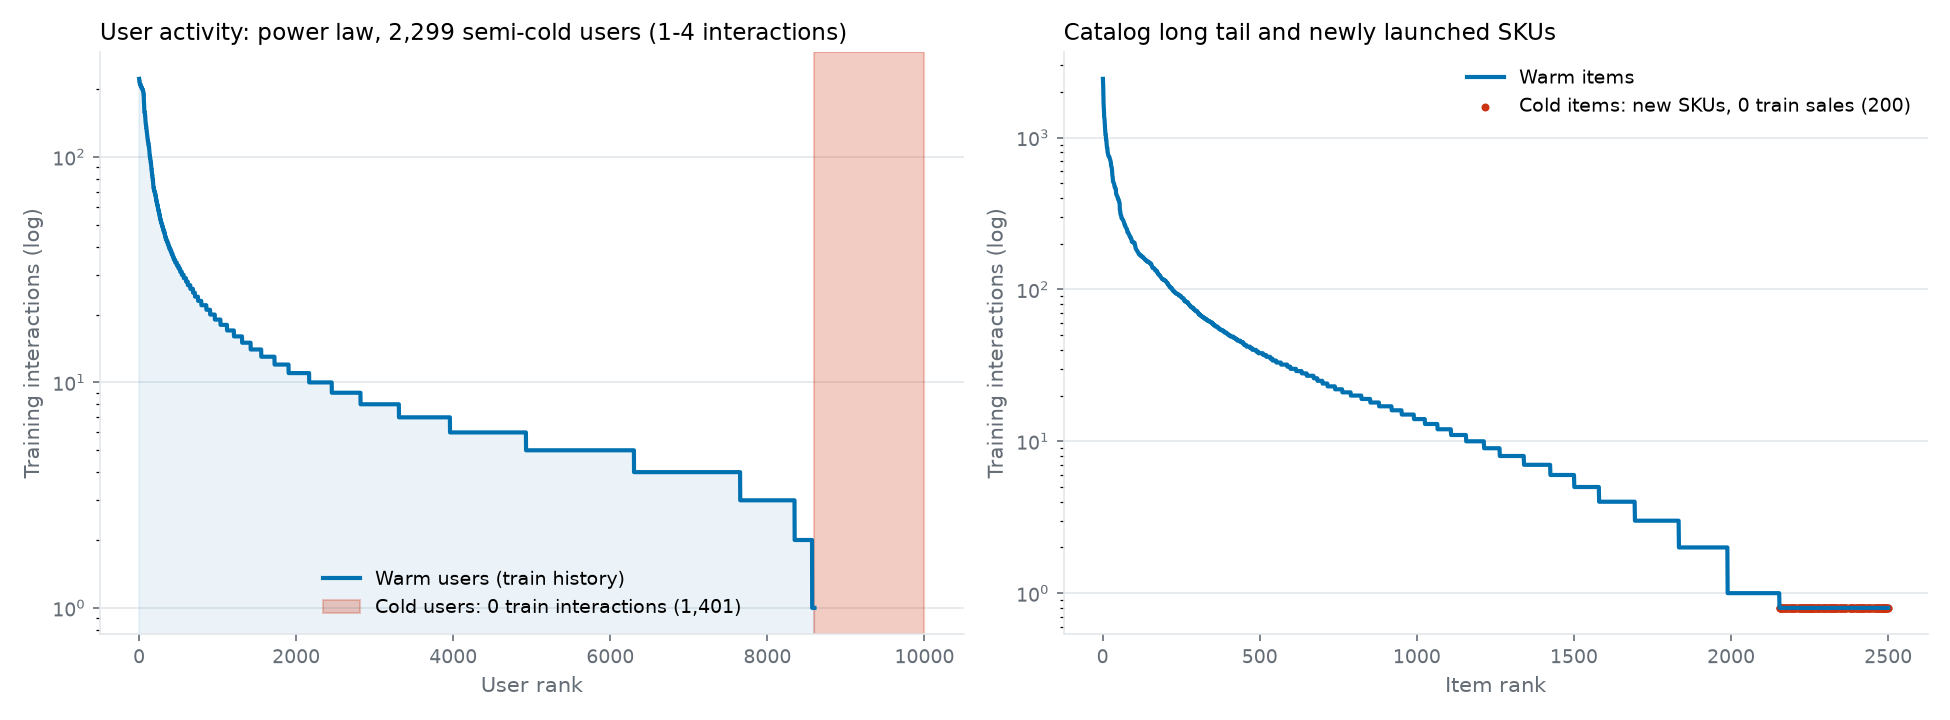

In [16]:
with sl.stage("eda_charts"):
    plot_cold_start_distribution(ds.interactions, ds.users, ds.items, P["charts"] / "cold_start_distribution.png")
display(Image(str(P["charts"] / "cold_start_distribution.png")))

## 6. Preprocess, fit popularity / content / bandit

In [17]:
with sl.stage("preprocess") as rec:
    pre = Preprocessor(cfg).fit(ds)
    train, val = pre.build_rows(ds, ["train"]), pre.build_rows(ds, ["val"])
    cases = pre.build_eval_cases(ds, int(cfg["eval"]["n_eval_users"]), cfg["seed"])
sl.info(f"embeddings={pre.embedder.backend} content_dim={pre.content_dim} train={len(train['item_pos'])} val={len(val['item_pos'])} cases={ {k: len(v) for k, v in cases.items()} }")
with sl.stage("fit_popularity_content_bandit"):
    tv = ds.interactions[ds.interactions.split.isin(["train", "val"])]
    pop = ContextualPopularity(cfg).fit(tv, ds.users, pre.item_pos, now_day=CUTOFF_DAY)
    index = ItemIndex(pre.content_dim, cfg["hardware"]["faiss_gpu"]); index.build(pre.item_content)
    content = ContentBasedRecommender(index)
    bandit = ContextualBandit(pre, cfg, cfg["seed"])
    subidx = np.array([bandit.arm_idx.get(s, 0) for s in pre.item_subcat])
    n_rep = bandit.fit_replay(tv, ds.users, subidx)
sl.info(f"faiss={index.backend} popularity segments={len(pop.seg_share)} bandit replay events={n_rep}")

17:31:56 | INFO    | > START  preprocess


17:31:59 | INFO    | OK DONE  preprocess (2.945s)


17:31:59 | INFO    | embeddings=tfidf_svd content_dim=160 train=63320 val=7100 cases={'warm': 1500, 'cold_user': 999, 'cold_item': 922, 'session': 382}


17:31:59 | INFO    | > START  fit_popularity_content_bandit


17:32:02 | INFO    | OK DONE  fit_popularity_content_bandit (2.747s)


17:32:02 | INFO    | faiss=faiss-cpu popularity segments=25 bandit replay events=60000


## 7. Train the Two-Tower (ID dropout + AMP)

17:32:02 | INFO    | > START  train_two_tower


17:32:04 | INFO    |   epoch 01 train_loss=7.7402 val_loss=7.5598 val_R@10=0.1667 (0.97s, amp=True)


17:32:04 | INFO    |   epoch 02 train_loss=7.0795 val_loss=7.1218 val_R@10=0.1940 (0.37s, amp=True)


17:32:04 | INFO    |   epoch 03 train_loss=6.7656 val_loss=7.0966 val_R@10=0.1987 (0.4s, amp=True)


17:32:05 | INFO    |   epoch 04 train_loss=6.5654 val_loss=6.9501 val_R@10=0.1923 (0.37s, amp=True)


17:32:05 | INFO    |   epoch 05 train_loss=6.4576 val_loss=6.9929 val_R@10=0.1832 (0.38s, amp=True)


17:32:06 | INFO    |   epoch 06 train_loss=6.3912 val_loss=7.0434 val_R@10=0.1740 (0.39s, amp=True)


17:32:06 | INFO    | OK DONE  train_two_tower (4.009s)


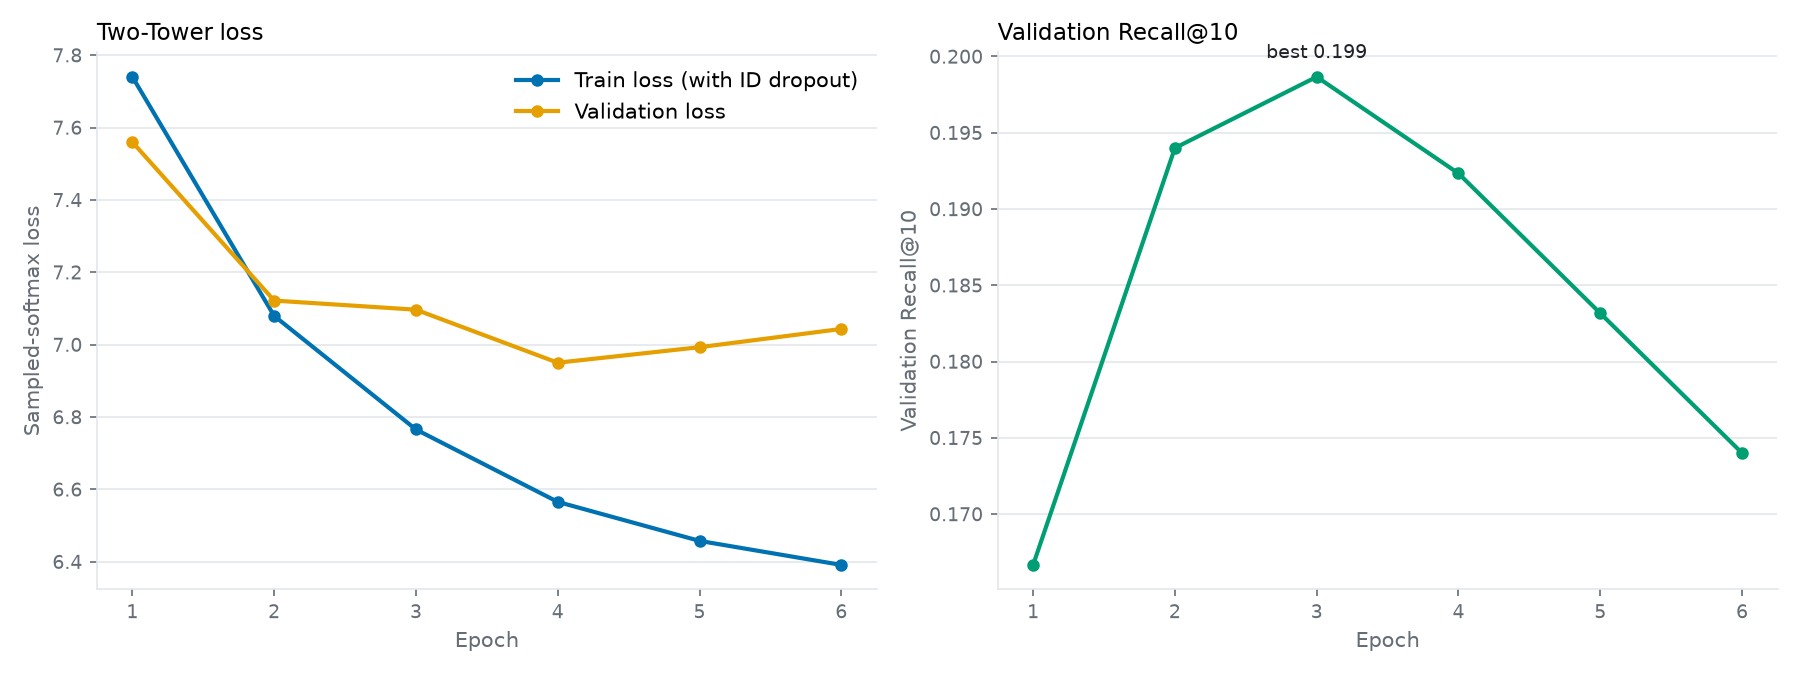

In [18]:
with sl.stage("train_two_tower"):
    tower = TwoTowerRecommender(pre, cfg, device)
    hist = tower.fit(train, val, log=sl.info)
    tower.save(P["models"])
pd.DataFrame(hist).to_csv(P["metrics"] / "two_tower_training_history.csv", index=False)
plot_training_curve(hist, P["charts"] / "two_tower_training_curve.png")
display(Image(str(P["charts"] / "two_tower_training_curve.png")))

## 8. Assemble the router and evaluate all strategies by coldness tier

17:32:06 | INFO    | > START  evaluate_strategies


17:32:20 | INFO    | OK DONE  evaluate_strategies (13.843s)


tier,cold_item,cold_user,session,warm
strategy,,,,
Content-Based,0.3177,0.0186,0.0140,0.0246
Hybrid Meta-Router,0.2127,0.1786,0.1099,0.1193
Popularity,0.0493,0.1452,0.1353,0.1152
Random,0.0613,0.0052,0.0039,0.0042
Two-Tower (ID Dropout),0.1913,0.1305,0.1248,0.1202


,strategy,tier,n_cases,recall@10,ndcg@10,hit_rate@10,coverage,cold_item_coverage,novelty,serendipity,lift_vs_popularity
0,Random,warm,1500,0.0042,0.0020,0.0073,1.0000,0.000,12.8640,0.0005,-0.9633
1,Random,cold_user,999,0.0052,0.0037,0.0250,0.9820,0.975,13.1197,0.0016,-0.9645
2,Random,cold_item,922,0.0613,0.0287,0.0738,1.0000,1.000,16.1540,0.0075,0.2425
3,Random,session,382,0.0039,0.0026,0.0079,0.7832,0.835,13.2042,0.0008,-0.9710
4,Popularity,warm,1500,0.1152,0.0709,0.1993,0.0109,0.000,6.5591,0.0004,0.0000
5,Popularity,cold_user,999,0.1452,0.1185,0.5225,0.0056,0.000,6.4781,0.0000,0.0000
6,Popularity,cold_item,922,0.0493,0.0213,0.0586,1.0000,1.000,16.1540,0.0060,0.0000
7,Popularity,session,382,0.1353,0.0867,0.2408,0.0080,0.000,6.4960,0.0000,0.0000
8,Content-Based,warm,1500,0.0246,0.0135,0.0460,0.9378,0.000,12.8534,0.0043,-0.7865
9,Content-Based,cold_user,999,0.0186,0.0145,0.0901,0.4600,0.730,13.4055,0.0066,-0.8719


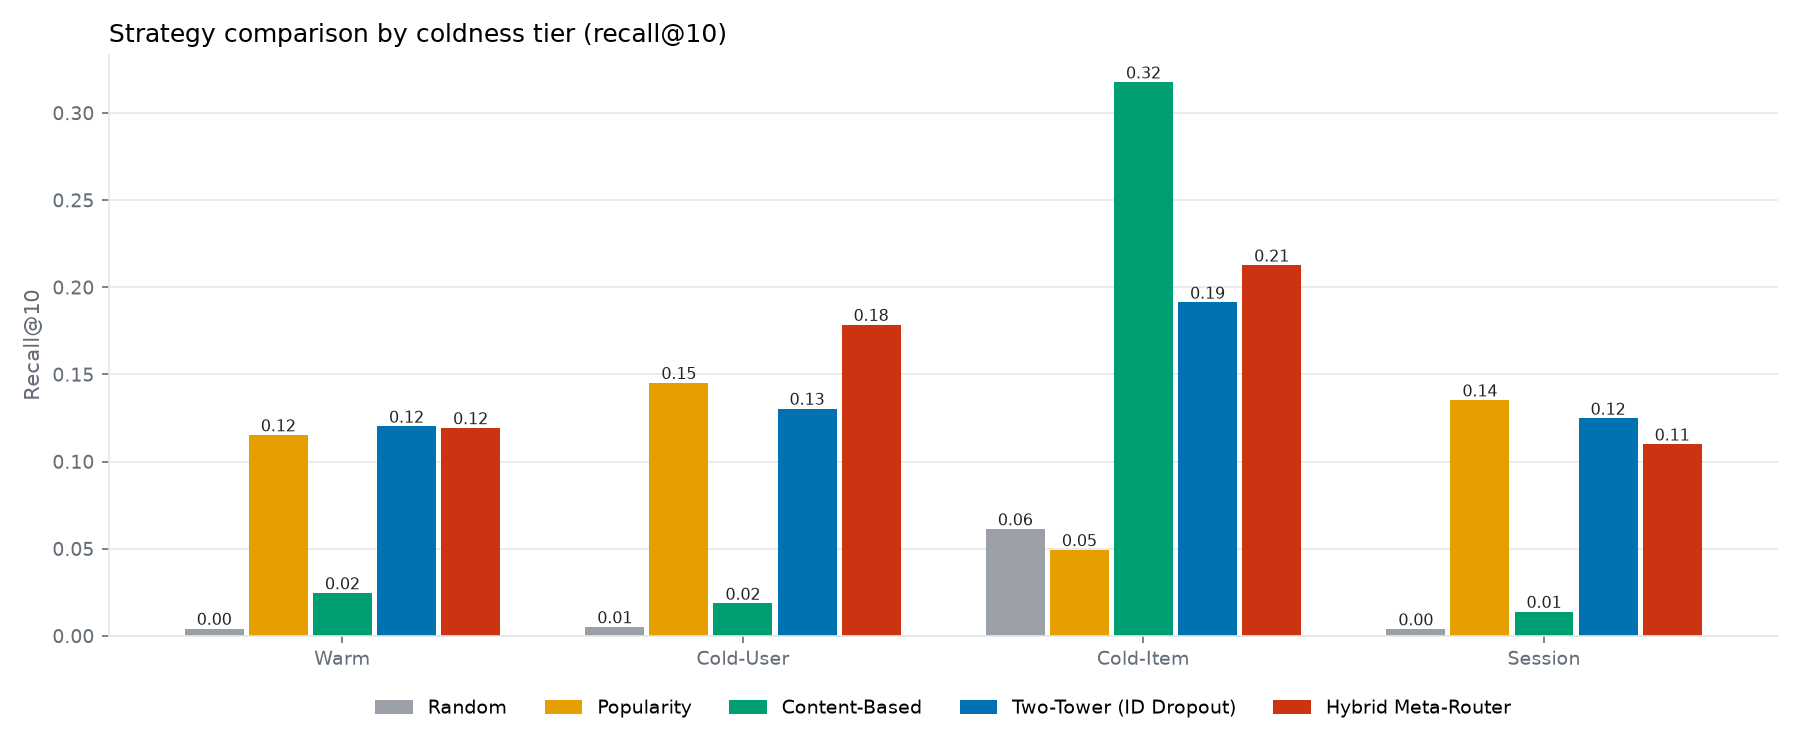

In [19]:
sales = np.bincount(tv[tv.positive == 1].item_id.map(pre.item_pos).values, minlength=len(pre.item_ids)).astype(float)
router = MetaRouter(cfg, pre, ds.items, pop, index, tower, bandit, sales)
K = int(cfg["eval"]["k"]); n_items = len(pre.item_ids); rng = np.random.default_rng(cfg["seed"])
pop_top = set(np.argsort(-sales)[:50].tolist())
n_cands = {"warm": int((~pre.is_cold_item).sum()), "cold_user": n_items, "cold_item": int(pre.is_cold_item.sum()), "session": n_items}
def pctx(c): return dict(region=c.user_row.get("region"), device=c.user_row.get("device"), acq_channel=c.user_row.get("acq_channel"), season=c.ctx["season"], hour=c.ctx["hour"], channel=c.ctx["channel"])
def rank(scores, c): return top_k_from_scores(scores + rng.random(len(scores)) * 1e-9, c.candidates, c.exclude, K)
strategies = {
    "Random": lambda c: rank(rng.random(n_items), c),
    "Popularity": lambda c: rank(pop.score_all(pctx(c))[:n_items], c),
    "Content-Based": lambda c: rank(content.score_all(pre.profile_vec(c.history, c.user_row.get("onboarding_categories")), n_items), c),
    "Two-Tower (ID Dropout)": lambda c: rank(tower.score_all(c.user_row, c.ctx, c.history), c),
    "Hybrid Meta-Router": lambda c: [i.position for i in router.recommend(c.user_row, c.ctx, c.history, k=K, exclude=c.exclude, candidates=c.candidates, explore=False).items],
}
rows = []
with sl.stage("evaluate_strategies"):
    for name, fn in strategies.items():
        rows += evaluate_strategy(name, fn, cases, K, sales, pre.is_cold_item, n_cands, pop_top)
df = add_cold_start_lift(pd.DataFrame(rows), f"recall@{K}")
df.to_csv(P["metrics"] / "cold_start_eval_metrics.csv", index=False)
(P["metrics"] / "cold_start_eval_metrics.json").write_text(df.to_json(orient="records", indent=2))
plot_strategy_comparison(df, P["charts"] / "strategy_comparison_benchmark.png", f"recall@{K}")
display(df.pivot(index="strategy", columns="tier", values=f"recall@{K}").round(4))
display(df.round(4))
display(Image(str(P["charts"] / "strategy_comparison_benchmark.png")))

## 9. Exploration trade-off: new-item slots vs accuracy and cold-item coverage

17:32:20 | INFO    | > START  coverage_novelty_sweep


17:32:41 | INFO    | OK DONE  coverage_novelty_sweep (21.262s)


,label,slots,recall,cold_item_coverage
0,0 slots,0,0.1135,0.290
1,1 slots,1,0.1077,0.790
2,2 slots,2,0.1036,0.925
3,3 slots,3,0.0981,0.945
4,4 slots,4,0.0933,0.980
5,5 slots,5,0.0850,0.985


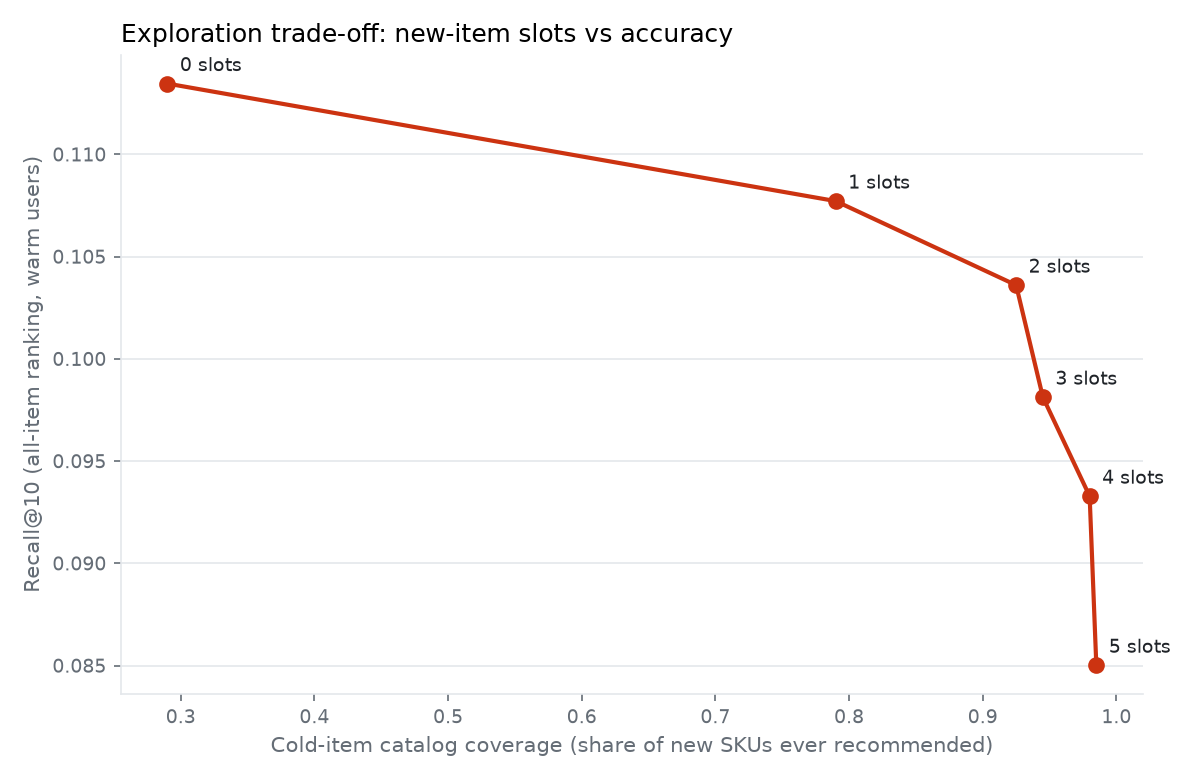

In [20]:
with sl.stage("coverage_novelty_sweep"):
    pos = ds.interactions[(ds.interactions.positive == 1) & (ds.interactions.split == "test_cold_item")]
    cold_t = pos.groupby("user_id")["item_id"].apply(lambda s: {pre.item_pos[i] for i in s}).to_dict()
    mixed = [EvalCase(c.split, c.user_id, c.user_row, c.ctx, c.history, sorted(set(c.targets) | cold_t.get(c.user_id, set())), None, c.exclude) for c in cases["warm"]]
    pts = []
    for slots in range(0, 6):
        router.new_slots = slots
        recs = [[i.position for i in router.recommend(c.user_row, c.ctx, c.history, k=K, exclude=c.exclude, include_new_items_boost=slots > 0, explore=False).items] for c in mixed]
        pts.append(dict(label=f"{slots} slots", slots=slots, recall=float(np.mean([recall_at_k(r, set(c.targets), K) for r, c in zip(recs, mixed)])),
                        cold_item_coverage=catalog_coverage([[i for i in r if pre.is_cold_item[i]] for r in recs], int(pre.is_cold_item.sum()))))
    router.new_slots = int(cfg["router"]["new_item_slots"])
pdf = pd.DataFrame(pts); pdf.to_csv(P["metrics"] / "coverage_vs_recall.csv", index=False)
plot_coverage_novelty(pdf, P["charts"] / "catalog_coverage_novelty.png")
display(pdf.round(4)); display(Image(str(P["charts"] / "catalog_coverage_novelty.png")))

## 10. The four cold-start scenarios, served directly through the router (no API)

In [21]:
def show(title, urow, ctx, history, **kw):
    r = router.recommend(urow, ctx, history, k=8, **kw)
    print(f"\n=== {title} | strategy={r.strategy} | interactions={r.n_interactions} | {r.latency_ms:.1f} ms | weights={r.components}")
    out = pd.DataFrame([dict(rank=n+1, item=i.item_id, title=router.meta[i.position]["title"], subcat=router.meta[i.position]["subcat"],
                             new=i.is_new_item, score=round(i.score, 3), why=" | ".join(i.tags)) for n, i in enumerate(r.items)])
    display(out)
ctx0 = dict(channel="app", season="winter", hour=20)
show("1. Anonymous zero-history user", dict(region="north", device="ios"), ctx0, [])
show("2. Onboarding new user", dict(region="west", device="android", acq_channel="paid_social", onboarding_categories=["Audio", "Wearables"]), dict(channel="app", season="winter", hour=9), [])
run_ids = ds.items[ds.items.subcat == "Running Shoes"].item_id.head(3).tolist()
show("3. Session clickstream user (3 clicks on running shoes)", {}, dict(channel="web", season="winter", hour=14), [pre.item_pos[i] for i in run_ids])
warm_u = next(u for u, h in tv[tv.positive == 1].groupby("user_id").size().items() if h >= 8)
wh = tv[(tv.user_id == warm_u) & (tv.positive == 1)].sort_values("ts").item_id.map(pre.item_pos).tolist()
wr = ds.users.set_index("user_id").loc[warm_u].to_dict(); wr["user_id"] = warm_u
show(f"3b. Warm user {warm_u}", wr, ctx0, wh, exclude=set(wh))


=== 1. Anonymous zero-history user | strategy=cold_zero_history | interactions=0 | 4.0 ms | weights={'pop': 0.44999999999999996, 'tt': 0.4, 'content': 0.0, 'bandit': 0.15}


,rank,item,title,subcat,new,score,why
0,1,SKU00169,Iris Works Minimal Red Soccer Ball,Team Sports,False,0.925,"Contextual Popularity (north/ios, winter) | On..."
1,2,SKU02317,Aria Works Modern Tan Baseball Glove,Team Sports,False,0.925,"Contextual Popularity (north/ios, winter) | On..."
2,3,SKU01741,Volt Goods Minimal Grey Storage Bin,Storage,False,0.891,"Contextual Popularity (north/ios, winter) | On..."
3,4,SKU01624,Kite Goods Eco Grey Phone Case,Smartphones,False,0.872,"Contextual Popularity (north/ios, winter) | On..."
4,5,SKU00050,Orbit &Sons Modern Pink Basketball,Team Sports,False,0.859,"Contextual Popularity (north/ios, winter) | On..."
5,6,SKU02461,Fjord Goods Eco Teal Mascara,Makeup,False,0.854,"Contextual Popularity (north/ios, winter) | On..."
6,7,SKU02168,Aria Labs Pro Black Trampoline,Outdoor Play,False,0.845,"Contextual Popularity (north/ios, winter) | On..."
7,8,SKU01427,Sol Works Modern Red Sparkling Water,Beverages,False,0.837,"Contextual Popularity (north/ios, winter) | On..."



=== 2. Onboarding new user | strategy=cold_zero_history | interactions=0 | 2.4 ms | weights={'pop': 0.15, 'tt': 0.4, 'content': 0.3, 'bandit': 0.15}


,rank,item,title,subcat,new,score,why
0,1,SKU02113,Halo Co Classic Navy Wireless Earbuds,Audio,False,0.839,Onboarding Category + Two-Tower | Onboarding C...
1,2,SKU01701,Halo Co Eco Pink Smartwatch,Wearables,False,0.770,Onboarding Category + Two-Tower | Onboarding C...
2,3,SKU02388,Kite Goods Vintage Pink Over-Ear Headphones,Audio,False,0.716,Onboarding Category + Two-Tower | Onboarding C...
3,4,SKU01624,Kite Goods Eco Grey Phone Case,Smartphones,False,0.700,Onboarding Category + Two-Tower | Contextual P...
4,5,SKU00574,Halo Co Classic Sand Smartwatch,Wearables,False,0.684,Onboarding Category + Two-Tower | Onboarding C...
5,6,SKU01703,Halo Co Pro Teal Soundbar,Audio,False,0.684,Onboarding Category Similarity | Onboarding Ca...
6,7,SKU02470,Aria Studio Pro Red Mechanical Keyboard,Computing,False,0.665,Onboarding Category + Two-Tower | Onboarding C...
7,8,SKU01060,Maple Labs Eco Navy Bluetooth Speaker,Audio,False,0.640,Onboarding Category + Two-Tower | Onboarding C...



=== 3. Session clickstream user (3 clicks on running shoes) | strategy=semi_cold_session | interactions=3 | 2.3 ms | weights={'pop': 0.1, 'tt': 0.5, 'content': 0.3, 'bandit': 0.1}


,rank,item,title,subcat,new,score,why
0,1,SKU00006,Volt &Sons Pro White Trail Runner,Running Shoes,False,0.823,Session-Aware Two-Tower | Session Content Simi...
1,2,SKU00032,Echo Works Classic Sand Marathon Flat,Running Shoes,False,0.814,Session-Aware Two-Tower | Session Content Simi...
2,3,SKU00175,Atlas Works Classic Teal Road Racer,Running Shoes,False,0.808,Session-Aware Two-Tower | Session Content Simi...
3,4,SKU00317,Atlas Works Eco Sand Road Racer,Running Shoes,False,0.757,Session-Aware Two-Tower | Session Content Simi...
4,5,SKU00664,Echo Works Vintage Red Slip-On,Casual Sneakers,False,0.742,Session-Aware Two-Tower | Session Content Simi...
5,6,SKU00853,Volt &Sons Classic Teal Flip Flop,Sandals,False,0.730,Session-Aware Two-Tower | Session Content Simi...
6,7,SKU01589,Atlas Works Classic Pink Marathon Flat,Running Shoes,False,0.716,Session-Aware Two-Tower | Session Content Simi...
7,8,SKU00591,Atlas Works Modern Pink Marathon Flat,Running Shoes,True,0.681,Session-Aware Two-Tower | Matched via New-Item...



=== 3b. Warm user U00008 | strategy=warm_personalized | interactions=11 | 3.2 ms | weights={'pop': 0.0, 'tt': 0.85, 'content': 0.0, 'bandit': 0.15}


,rank,item,title,subcat,new,score,why
0,1,SKU00032,Echo Works Classic Sand Marathon Flat,Running Shoes,False,0.878,Personalized Two-Tower | LinUCB Exploration
1,2,SKU01974,Iris Works Casual Sand Pasta,Pantry,False,0.863,Personalized Two-Tower | LinUCB Exploration
2,3,SKU00579,Apex Labs Minimal Sand Sea Salt Chips,Snacks,False,0.810,Personalized Two-Tower | LinUCB Exploration
3,4,SKU01427,Sol Works Modern Red Sparkling Water,Beverages,False,0.788,Personalized Two-Tower
4,5,SKU01483,Zen Studio Pro White Weighted Blanket,Bedding,False,0.782,Personalized Two-Tower
5,6,SKU02281,Apex Labs Bold Black Pasta,Pantry,False,0.687,Personalized Two-Tower | LinUCB Exploration
6,7,SKU02034,Atlas Works Pro Olive Chelsea Boot,Boots,False,0.659,Personalized Two-Tower
7,8,SKU00990,Apex Labs Minimal Pink Organic Nut Butter,Organic,False,0.649,Personalized Two-Tower


### 4. Newly onboarded SKU: embed on the fly and inject into the live FAISS index

In [22]:
new_sku = dict(item_id="SKU_LIVE_001", title="Aero Trail Runner Pro", brand="Nova Works",
               description="Lightweight trail running shoe with grippy sole, cushion and breathable mesh.",
               dept="Footwear", subcat="Running Shoes", price=119.0, leaf="trail runner", color="teal", style="pro")
before = index.size; t = time.perf_counter(); pos_new = router.onboard_item(new_sku); ms = (time.perf_counter() - t) * 1000
print(f"onboarded at position {pos_new} in {ms:.1f} ms; FAISS size {before} -> {index.size}")
show("4. New-SKU injection (include_new_items_boost=True)", dict(region="south", onboarding_categories=["Running Shoes"]), dict(channel="web", season="winter", hour=7), [], include_new_items_boost=True)

onboarded at position 2500 in 6.0 ms; FAISS size 2500 -> 2501

=== 4. New-SKU injection (include_new_items_boost=True) | strategy=cold_zero_history | interactions=0 | 2.3 ms | weights={'pop': 0.15, 'tt': 0.4, 'content': 0.3, 'bandit': 0.15}


,rank,item,title,subcat,new,score,why
0,1,SKU00032,Echo Works Classic Sand Marathon Flat,Running Shoes,False,0.759,Onboarding Category + Two-Tower | Onboarding C...
1,2,SKU_LIVE_001,Aero Trail Runner Pro,Running Shoes,True,0.293,Matched via New-Item Semantic Similarity
2,3,SKU00175,Atlas Works Classic Teal Road Racer,Running Shoes,False,0.729,Onboarding Category + Two-Tower | Onboarding C...
3,4,SKU00006,Volt &Sons Pro White Trail Runner,Running Shoes,False,0.676,Onboarding Category Similarity | Onboarding Ca...
4,5,SKU00021,Atlas Co Bold Pink Marathon Flat,Running Shoes,True,0.280,Matched via New-Item Semantic Similarity
5,6,SKU00317,Atlas Works Eco Sand Road Racer,Running Shoes,False,0.640,Onboarding Category + Two-Tower | Onboarding C...
6,7,SKU02034,Atlas Works Pro Olive Chelsea Boot,Boots,False,0.640,Onboarding Category + Two-Tower | Onboarding C...
7,8,SKU00664,Echo Works Vintage Red Slip-On,Casual Sneakers,False,0.629,Onboarding Category + Two-Tower | Contextual P...


### Online learning: feedback updates the LinUCB bandit

In [23]:
x = bandit.context_vector(dict(region="central", device="desktop"), dict(channel="web", season="winter", hour=9))
arm = int(router.subcat_idx[5]); b0 = bandit.arm_scores(x, explore=False)[arm]
for _ in range(30): bandit.update(x, arm, REWARD["purchase"], 5)
print(f"arm '{bandit.arms[arm]}' expected reward {b0:.4f} -> {bandit.arm_scores(x, explore=False)[arm]:.4f} after 30 purchases")

arm 'Casual Sneakers' expected reward 0.3352 -> 0.9368 after 30 purchases


## 11. Inference latency benchmark (router, in-process)

In [24]:
with sl.stage("latency_benchmark"):
    r_ = np.random.default_rng(1); n_req = int(cfg["eval"]["latency_requests"])
    warm_users = ds.users[ds.users.user_type == "warm"].user_id.tolist()[:300]
    uh = tv[tv.positive == 1].sort_values("ts").groupby("user_id")["item_id"].apply(lambda s: [pre.item_pos[i] for i in s]).to_dict()
    urows = ds.users.set_index("user_id").to_dict("index")
    cold_users = ds.users[ds.users.user_type == "cold"].to_dict("records")
    lat = {"warm_user": [], "cold_user_onboarding": [], "session_clickstream": [], "anonymous": []}
    for i in range(n_req + 10):
        m = i % 4; ctx = dict(channel="web", season="winter", hour=int(r_.integers(24)))
        t = time.perf_counter()
        if m == 0:
            u = warm_users[int(r_.integers(len(warm_users)))]; ur = dict(urows[u]); ur["user_id"] = u; router.recommend(ur, ctx, uh.get(u, []), k=K, exclude=set(uh.get(u, [])))
        elif m == 1:
            u = cold_users[int(r_.integers(len(cold_users)))]; router.recommend(u, ctx, [], k=K, include_new_items_boost=True)
        elif m == 2:
            router.recommend({}, ctx, [int(x) for x in r_.integers(0, n_items, 3)], k=K)
        else:
            router.recommend(dict(region="north"), ctx, [], k=K)
        if i >= 10: lat[list(lat)[m]].append((time.perf_counter() - t) * 1000)
    q = pre.item_content[r_.integers(0, n_items, 500)]; fl = []
    for v in q:
        t = time.perf_counter(); index.search(v, 10); fl.append((time.perf_counter() - t) * 1000)
def pct(ms): a = np.asarray(ms); return {"p50_ms": float(np.percentile(a, 50)), "p95_ms": float(np.percentile(a, 95)), "p99_ms": float(np.percentile(a, 99)), "n": len(a)}
bench = dict(device=str(device), overall=pct(sum(lat.values(), [])), by_scenario={k: pct(v) for k, v in lat.items()}, faiss_search_top10=pct(fl), faiss_backend=index.backend)
(P["metrics"] / "inference_latency_benchmark.json").write_text(json.dumps(bench, indent=2)); print(json.dumps(bench, indent=2))

17:32:41 | INFO    | > START  latency_benchmark


17:32:42 | INFO    | OK DONE  latency_benchmark (1.161s)


{
  "device": "cuda",
  "overall": {
    "p50_ms": 2.0804500018130057,
    "p95_ms": 3.7419649997900706,
    "p99_ms": 5.294693998439469,
    "n": 400
  },
  "by_scenario": {
    "warm_user": {
      "p50_ms": 2.229750003607478,
      "p95_ms": 3.9731299882987505,
      "p99_ms": 4.933510996197584,
      "n": 100
    },
    "cold_user_onboarding": {
      "p50_ms": 2.1757000067736953,
      "p95_ms": 3.264364998904056,
      "p99_ms": 5.295168998563896,
      "n": 100
    },
    "session_clickstream": {
      "p50_ms": 2.0612000007531606,
      "p95_ms": 2.673865002725506,
      "p99_ms": 5.413971991074505,
      "n": 100
    },
    "anonymous": {
      "p50_ms": 1.7665500054135919,
      "p95_ms": 3.835479989356827,
      "p99_ms": 4.203565004572745,
      "n": 100
    }
  },
  "faiss_search_top10": {
    "p50_ms": 0.03609999839682132,
    "p95_ms": 0.03931000755983404,
    "p99_ms": 0.05843999373610128,
    "n": 500
  },
  "faiss_backend": "faiss-cpu"
}


## 12. Save artifacts and pipeline summary

In [25]:
index.save(P["models"] / "item_index.faiss"); bandit.save(P["models"])
(P["models"] / "scalers.json").write_text(json.dumps(dict(price_mu=pre.price_mu, price_sd=pre.price_sd)))
summ = sl.write_summary({"notebook": True})
print("saved models:", sorted(p.name for p in P["models"].iterdir())); print("all stages ok:", summ["all_ok"], "| total seconds:", summ["total_seconds"])
pd.DataFrame(summ["stages"])[["stage", "status", "seconds"]]

saved models: ['bandit.pkl', 'item_index.faiss', 'scalers.json', 'two_tower.pt']
all stages ok: True | total seconds: 56.616


,stage,status,seconds
0,hardware_diagnostics,ok,0.003
1,generate_data,ok,8.751
2,eda_charts,ok,0.362
3,preprocess,ok,2.945
4,fit_popularity_content_bandit,ok,2.747
5,train_two_tower,ok,4.009
6,evaluate_strategies,ok,13.843
7,coverage_novelty_sweep,ok,21.262
8,latency_benchmark,ok,1.161
